# Controlled two-task paradigm: A → B → A

**Question.** When a one-module network learns task B after task A, how does A's
geometry change? How much of the change is set by the task relation (Hamming(A, B),
input change s_f) and how much by the learner (richness γ₀)? What does relearning A
recover?

**Slot.** `docs/26` Part B, two-task paradigm: the controlled experiment that comes
before the stream (Kati, 2026-11-06). It is part of the `docs/24` §4 core.

**Pre-commit.** `docs/28` (signed 2026-11-09). Its readings are computed in section 8 and are
the only confirmatory part. Everything else here is observation.

**Self-contained.** Everything lives in `aba_lib.py` next to this notebook: the
generator, the 1M network, training, NTK, and a vendored copy of GLUE. Section 3
asserts that the GLUE copy matches `src.glue.core`.

## 1. Config

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[_v] = "1"          # before numpy is imported anywhere in this kernel

# Mode comes from the environment so the committed notebook runs unchanged in both places:
#   laptop:  QUICK (M=50, n_t=50, n=3);   cluster job: ABA_MODE=full (M=150, n_t=200, n=8).
QUICK = os.environ.get("ABA_MODE", "quick") == "quick"
RUN_GRID = os.environ.get("ABA_RUN_GRID", "1") == "1"      # 0: read the checkpoint only
WORKERS = int(os.environ.get("ABA_WORKERS", "6"))          # spawned workers; 6 is the laptop cap

import sys, time, json, math
from pathlib import Path
here = Path.cwd().resolve()
REPO = next(p for p in [here, *here.parents] if (p / ".git").exists())
sys.path[:0] = [str(REPO / "notebooks" / "core"), str(REPO)]

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import aba_lib as L

cfg = L.ABAConfig.make(QUICK)
STAMP = L.git_stamp()

def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

md_table(["parameter", "value"], [[k, v] for k, v in vars(cfg).items()])
print(f"aba_lib hash {L.lib_hash()}   commit {STAMP['commit']}   dirty {STAMP['dirty']}")
print(f"numpy {np.__version__}   python {sys.version.split()[0]}   cache {L.cache_path(cfg).relative_to(REPO)}")

| parameter | value |
|---|---|
| quick | False |
| P | 16 |
| d | 150 |
| D | 4 |
| R | 1.0 |
| M | 150 |
| N | 300 |
| lr0 | 5.0 |
| n_base | 64 |
| target_loss | 0.05 |
| max_steps | 20000 |
| record_every | 25 |
| n_t | 200 |
| center_policy | all |
| ntk_per_manifold | 20 |
| probe_hamming | 4 |
| n_probe_neutral | 4 |
| refit_steps | 2000 |
| bottleneck_n | 16 |
| gammas | (0.1, 1.0, 10.0) |
| hammings | (0, 4, 8) |
| s_fs | (1.0, 0.9, 0.1) |
| n_seeds | 8 |

aba_lib hash 2528909f2feaf3f3   commit a7f03989886f   dirty False
numpy 2.4.6   python 3.11.16   cache results/aba/FULL_2528909f2feaf3f3.jsonl


In [2]:
# Palette: reference categorical order (blue, orange, aqua); diverging blue ↔ orange through a neutral grey.
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
GAMMA_COL = dict(zip(cfg.gammas, [BLUE, AQUA, ORANGE]))   # γ0 = 0.1, 1, 10; validated (dataviz), legends + tables carry identity
LABEL_COL = {1: BLUE, -1: ORANGE}
from matplotlib.colors import LinearSegmentedColormap
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2.0, "font.size": 9})
CHECKS = []   # (check, PASS/FAIL, detail): validation checks, kept apart from observations
def check(name, ok, detail=""):
    CHECKS.append((name, "PASS" if ok else "**FAIL**", detail))
    print(("PASS " if ok else "FAIL ") + name + (f"  ({detail})" if detail else ""))

## 2. Manifolds

Seed 0 is shown. A and y_A are shared by every cell and both γ₀. B is A's
arrangement with centres redrawn at ρ = s_f (axes and shapes held), labelled by a
dichotomy at the stated Hamming distance from y_A. **At s_f = 1.0, B's points are
A's points exactly.**

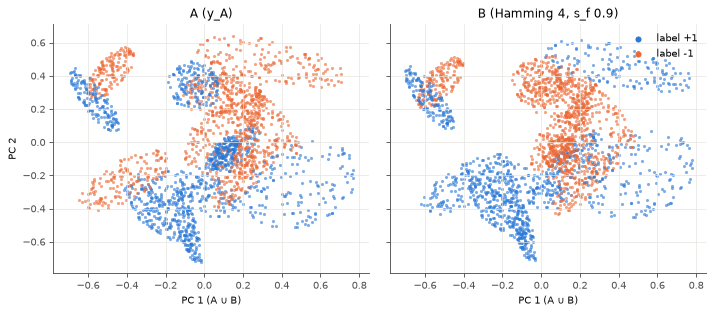

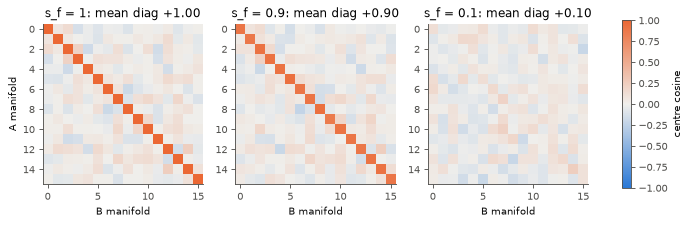

In [3]:
base = L.seed_base(cfg, 0)
H_SHOW, SF_SHOW = 4, 0.9
B_show = L.b_arrangement(cfg, base, SF_SHOW)
pts = np.concatenate([base.A.points.reshape(-1, cfg.d), B_show.points.reshape(-1, cfg.d)])
mu = pts.mean(0); _, _, Vt = np.linalg.svd(pts - mu, full_matrices=False); basis = Vt[:2]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, arr, y, title in [(axes[0], base.A, base.y_A, "A (y_A)"),
                          (axes[1], B_show, base.y_Bs[H_SHOW], f"B (Hamming {H_SHOW}, s_f {SF_SHOW})")]:
    for m in range(cfg.P):
        Z = (arr.points[m] - mu) @ basis.T
        ax.scatter(Z[:, 0], Z[:, 1], s=8, color=LABEL_COL[int(y[m])], alpha=0.6, linewidths=0)
    ax.set_title(title); ax.set_xlabel("PC 1 (A ∪ B)")
axes[0].set_ylabel("PC 2")
for lab, col in LABEL_COL.items():
    axes[1].scatter([], [], color=col, s=20, label=f"label {lab:+d}")
axes[1].legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.4))
for ax, sf in zip(axes, cfg.s_fs):
    C = L.centre_cosines(base.A.centers, L.b_arrangement(cfg, base, sf).centers)
    im = ax.imshow(C, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_title(f"s_f = {sf:g}: mean diag {np.mean(np.diag(C)):+.2f}"); ax.set_xlabel("B manifold"); ax.grid(False)
axes[0].set_ylabel("A manifold"); fig.colorbar(im, ax=axes, shrink=0.8, label="centre cosine"); plt.show()

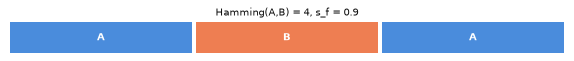

label relations, seed 0 (signed s_r = 1 − 2·Hamming/P):


| Hamming(A,B) | s_r(y_A, y_B) | s_r(y*, y_A) | s_r(y*, y_B) |
|---|---|---|---|
| 0 | +1.000 | +0.500 | +0.500 |
| 4 | +0.500 | +0.500 | +0.000 |
| 8 | +0.000 | +0.500 | +0.250 |

In [4]:
def stream_strip(ax, h, sf, widths=(1, 1, 1)):
    x = 0
    for (lab, col), w in zip([("A", BLUE), ("B", ORANGE), ("A", BLUE)], widths):
        ax.add_patch(plt.Rectangle((x + 0.01, 0), w - 0.02, 1, color=col, alpha=0.85, linewidth=0))
        ax.text(x + w / 2, 0.5, lab, ha="center", va="center", color="white", fontsize=9, weight="bold")
        x += w
    ax.set_xlim(0, x); ax.set_ylim(0, 1); ax.axis("off")
    ax.set_title(f"Hamming(A,B) = {h}, s_f = {sf:g}", fontsize=9, color=INK)

fig, ax = plt.subplots(figsize=(9, 0.5)); stream_strip(ax, H_SHOW, SF_SHOW); plt.show()
print("label relations, seed 0 (signed s_r = 1 − 2·Hamming/P):")
md_table(["Hamming(A,B)", "s_r(y_A, y_B)", "s_r(y*, y_A)", "s_r(y*, y_B)"],
         [[h, f"{L.s_r(base.y_A, yb):+.3f}", f"{L.s_r(base.y_star, base.y_A):+.3f}",
           f"{L.s_r(base.y_star, yb):+.3f}"] for h, yb in base.y_Bs.items()])

## 3. Estimator validation (must pass)

In [5]:
# (a) Vendored GLUE equals src.glue.core on one example, when src imports.
try:
    from src.glue.core import glue_measures as src_glue, Ensemble as SrcEnsemble
except Exception as e:  # noqa: BLE001
    src_glue = None; print("src not importable, comparison skipped:", e)
if src_glue is not None:
    mans = L.as_manifolds(base.A.points)
    y = base.y_A.astype(float)
    a = L.glue_measures(mans, np.random.default_rng(11), n_t=20, ensemble=L.Ensemble("retained", y)).to_dict()
    b = src_glue(mans, np.random.default_rng(11), n_t=20, ensemble=SrcEnsemble("retained", y)).to_dict()
    diff = max(abs(a[k] - b[k]) for k in a if isinstance(a[k], float))
    assert diff == 0.0, f"vendored GLUE differs from src.glue.core by {diff}"
    check("vendored GLUE == src.glue.core (retained y_A, input manifolds)", True, f"max |diff| = {diff:g}")

PASS vendored GLUE == src.glue.core (retained y_A, input manifolds)  (max |diff| = 0)


In [6]:
# (b) Identity residual and (c) capacity falls with R and with D, on input manifolds.
rows, alphas_R, alphas_D, resid = [], [], [], []
for R in (0.5, 1.0, 2.0):
    arr = L.make_arrangement(cfg.P, cfg.d, cfg.D, R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_R.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={R}, D={cfg.D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
for D in (2, 4, 8):
    arr = L.make_arrangement(cfg.P, cfg.d, D, cfg.R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_D.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={cfg.R}, D={D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
md_table(["input manifolds", "α (retained y_A)", "identity residual"], rows)
check("identity residual ≈ 0", max(resid) < 1e-10, f"max {max(resid):.1e}")
check("capacity falls as R grows (0.5 → 1 → 2)", bool(np.all(np.diff(alphas_R) < 0)), str([round(a, 4) for a in alphas_R]))
check("capacity falls as D grows (2 → 4 → 8)", bool(np.all(np.diff(alphas_D) < 0)), str([round(a, 4) for a in alphas_D]))

| input manifolds | α (retained y_A) | identity residual |
|---|---|---|
| R=0.5, D=4 | 0.6875 | 0.0e+00 |
| R=1.0, D=4 | 0.4208 | 0.0e+00 |
| R=2.0, D=4 | 0.2968 | 1.9e-16 |
| R=1.0, D=2 | 0.6475 | 1.7e-16 |
| R=1.0, D=4 | 0.4208 | 0.0e+00 |
| R=1.0, D=8 | 0.2899 | 0.0e+00 |

PASS identity residual ≈ 0  (max 1.9e-16)
PASS capacity falls as R grows (0.5 → 1 → 2)  ([0.6875, 0.4208, 0.2968])
PASS capacity falls as D grows (2 → 4 → 8)  ([0.6475, 0.4208, 0.2899])


In [7]:
# (d) Noise floor: SD of log α over K estimator seeds, on the init representation (identical across γ0).
K_FLOOR = 6 if QUICK else 8
net0 = L.OneModuleNet(base.W0, 1.0, cfg)
P_, M_, d_ = base.A.points.shape
Hrep = net0.hidden(base.A.points.reshape(-1, d_)).reshape(P_, M_, -1)
logs = [math.log(L.capacity(L.as_manifolds(Hrep), base.y_A, cfg, [L.SALT, 0, 1000 + k])["alpha"]) for k in range(K_FLOOR)]
FLOOR_INIT = float(np.std(logs, ddof=1))
print(f"INIT floor (reference only; hidden representation at initialisation, identical across γ0): "
      f"SD(log α) over {K_FLOOR} estimator seeds = {FLOOR_INIT:.4f}  (n_t = {cfg.n_t})")
print("Effects are resolved against the per-γ0 floors on the TRAINED representation (section 4).")

INIT floor (reference only; hidden representation at initialisation, identical across γ0): SD(log α) over 8 estimator seeds = 0.0196  (n_t = 200)
Effects are resolved against the per-γ0 floors on the TRAINED representation (section 4).


## 4. Network validation (must pass)

In [8]:
nets = {g: L.OneModuleNet(base.W0, g, cfg) for g in cfg.gammas}
XA, yA = L.flatten(base.A.points, base.y_A)
check("initial loss = 0.5 for every γ0", all(n.loss(XA, yA) == 0.5 for n in nets.values()),
      str({g: n.loss(XA, yA) for g, n in nets.items()}))
check("hidden init identical across γ0 (bitwise)", all(np.array_equal(nets[cfg.gammas[0]].W, nets[g].W) for g in cfg.gammas))
probe = np.concatenate([base.A.points[m, base.ntk_idx[m]] for m in range(cfg.P)])
_, KW0 = nets[cfg.gammas[0]].ntk_blocks(probe)
check("K_W(0) = 0 (readout starts at 0)", float(np.abs(KW0).max()) == 0.0)
tmp = L.OneModuleNet(base.W0, 1.0, cfg); tmp.u = np.random.default_rng(3).standard_normal(cfg.N)
fd = L.ntk_fd_check(tmp, probe[:3], np.random.default_rng(4))
check("analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference",
      fd["K_vs_JJt_rel"] < 1e-12 and fd["Jdelta_vs_fd_rel"] < 1e-5, str({k: f"{v:.1e}" for k, v in fd.items()}))

PASS initial loss = 0.5 for every γ0  ({0.1: 0.5, 1.0: 0.5, 10.0: 0.5})
PASS hidden init identical across γ0 (bitwise)
PASS K_W(0) = 0 (readout starts at 0)
PASS analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference  ({'K_vs_JJt_rel': '4.8e-16', 'Jdelta_vs_fd_rel': '6.8e-08'})


In [9]:
# Lazy/rich separation after A, and reaching the target within budget, for every seed and γ0.
sep_rows, sep, budget_ok = [], {}, []
for seed in range(cfg.n_seeds):
    b = L.seed_base(cfg, seed)
    X, y = L.flatten(b.A.points, b.y_A)
    pr = np.concatenate([b.A.points[m, b.ntk_idx[m]] for m in range(cfg.P)])
    yp = np.repeat(b.y_A.astype(float), b.ntk_idx.shape[1])
    for g in cfg.gammas:
        n = L.OneModuleNet(b.W0, g, cfg); Ku0, KW0 = n.ntk_blocks(pr)
        t = L.train_to_criterion(n, X, y, cfg)
        budget_ok.append((seed, g, t["status"], t["steps"]))
        sep[(seed, g)] = L.richness_snapshot(n, Ku0 + KW0, Ku0, pr, yp, pr, yp)[0]
display(Markdown("**NTK change after training on A: absolute values, not ratios.** All three are "
                  "‖·‖_F / ‖K(0)‖_F on A's fixed probe set; K(0) = K_u(0) because K_W(0) = 0. "
                  "ΔK_W is the hidden-weight block grown from zero; ΔK full = ‖ΔK_u + K_W‖."))
NTK_KEYS = [("dK_full", "ΔK full"), ("dK_u", "ΔK_u"), ("dK_W", "ΔK_W"), ("weight_change", "weight change")]
rows = []
for g in cfg.gammas:
    for seed in range(cfg.n_seeds):
        rows.append([f"{g:g}", seed] + [f"{sep[(seed, g)][k]:.4g}" for k, _ in NTK_KEYS])
    rows.append([f"**{g:g}**", "**mean**"] + [f"**{np.mean([sep[(s, g)][k] for s in range(cfg.n_seeds)]):.4g}**" for k, _ in NTK_KEYS])
md_table(["γ0", "seed"] + [lab for _, lab in NTK_KEYS], rows)
for k in ("weight_change", "dK_u", "dK_full"):
    check(f"increases with γ0 after A in {k}, every seed",
          all(sep[(s, hi)][k] > sep[(s, lo)][k] for s in range(cfg.n_seeds) for lo, hi in zip(cfg.gammas, cfg.gammas[1:])),
          "direction only; any ratio threshold is Kati's")
md_table(["seed", "γ0", "status", "steps on A"], [[s, f"{g:g}", st, n] for s, g, st, n in budget_ok])
check(f"every γ0 reaches loss {cfg.target_loss} within {cfg.max_steps} steps at lr0 = {cfg.lr0}",
      all(st == "converged" for _, _, st, _ in budget_ok), "a failure is reported, never re-pinned")

**NTK change after training on A: absolute values, not ratios.** All three are ‖·‖_F / ‖K(0)‖_F on A's fixed probe set; K(0) = K_u(0) because K_W(0) = 0. ΔK_W is the hidden-weight block grown from zero; ΔK full = ‖ΔK_u + K_W‖.

| γ0 | seed | ΔK full | ΔK_u | ΔK_W | weight change |
|---|---|---|---|---|---|
| 0.1 | 0 | 0.1854 | 0.04578 | 0.1613 | 0.01854 |
| 0.1 | 1 | 0.1824 | 0.04741 | 0.1585 | 0.01926 |
| 0.1 | 2 | 0.2068 | 0.04297 | 0.1855 | 0.02248 |
| 0.1 | 3 | 0.1989 | 0.04551 | 0.1743 | 0.02027 |
| 0.1 | 4 | 0.1986 | 0.04793 | 0.1736 | 0.02077 |
| 0.1 | 5 | 0.1863 | 0.0472 | 0.1621 | 0.01885 |
| 0.1 | 6 | 0.1871 | 0.04481 | 0.1638 | 0.02076 |
| 0.1 | 7 | 0.2002 | 0.04177 | 0.1806 | 0.02103 |
| **0.1** | **mean** | **0.1932** | **0.04542** | **0.17** | **0.02025** |
| 1 | 0 | 2.972 | 0.724 | 2.593 | 0.1493 |
| 1 | 1 | 2.797 | 0.7079 | 2.434 | 0.1486 |
| 1 | 2 | 3.075 | 0.6276 | 2.762 | 0.1626 |
| 1 | 3 | 3.134 | 0.7082 | 2.753 | 0.1548 |
| 1 | 4 | 3.001 | 0.7099 | 2.633 | 0.1556 |
| 1 | 5 | 2.941 | 0.7476 | 2.549 | 0.1491 |
| 1 | 6 | 2.919 | 0.6944 | 2.548 | 0.1567 |
| 1 | 7 | 3.016 | 0.6305 | 2.71 | 0.1588 |
| **1** | **mean** | **2.982** | **0.6938** | **2.623** | **0.1544** |
| 10 | 0 | 34.94 | 8.346 | 30.81 | 0.6076 |
| 10 | 1 | 31.54 | 7.903 | 27.67 | 0.5914 |
| 10 | 2 | 35.91 | 7.217 | 32.55 | 0.6511 |
| 10 | 3 | 36.78 | 8.334 | 32.58 | 0.6151 |
| 10 | 4 | 34.12 | 7.929 | 30.23 | 0.6175 |
| 10 | 5 | 33.48 | 8.648 | 29.06 | 0.6014 |
| 10 | 6 | 33.44 | 7.912 | 29.33 | 0.63 |
| 10 | 7 | 34.06 | 7.076 | 30.74 | 0.628 |
| **10** | **mean** | **34.28** | **7.921** | **30.37** | **0.6178** |

PASS increases with γ0 after A in weight_change, every seed  (direction only; any ratio threshold is Kati's)
PASS increases with γ0 after A in dK_u, every seed  (direction only; any ratio threshold is Kati's)
PASS increases with γ0 after A in dK_full, every seed  (direction only; any ratio threshold is Kati's)


| seed | γ0 | status | steps on A |
|---|---|---|---|
| 0 | 0.1 | converged | 1630 |
| 0 | 1 | converged | 311 |
| 0 | 10 | converged | 46 |
| 1 | 0.1 | converged | 1673 |
| 1 | 1 | converged | 304 |
| 1 | 10 | converged | 44 |
| 2 | 0.1 | converged | 1975 |
| 2 | 1 | converged | 359 |
| 2 | 10 | converged | 53 |
| 3 | 0.1 | converged | 1828 |
| 3 | 1 | converged | 328 |
| 3 | 10 | converged | 47 |
| 4 | 0.1 | converged | 1769 |
| 4 | 1 | converged | 328 |
| 4 | 10 | converged | 48 |
| 5 | 0.1 | converged | 1601 |
| 5 | 1 | converged | 305 |
| 5 | 10 | converged | 45 |
| 6 | 0.1 | converged | 1892 |
| 6 | 1 | converged | 342 |
| 6 | 10 | converged | 50 |
| 7 | 0.1 | converged | 1806 |
| 7 | 1 | converged | 342 |
| 7 | 10 | converged | 50 |

PASS every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0  (a failure is reported, never re-pinned)


In [10]:
# Noise floor per γ0 on the hidden representation AFTER training on A (seed 0, K estimator seeds).
FLOORS = {g: L.trained_floor(cfg, g, seed=0, K=K_FLOOR) for g in cfg.gammas}
md_table(["γ0", "floor SD(log α_A), trained", "K", "n_t", "mean log α_A after A"],
         [[f"{g:g}", f"{f['floor']:.4f}", f["K"], f["n_t"], f"{f['mean_log_alpha']:+.3f}"] for g, f in FLOORS.items()]
         + [["init (reference)", f"{FLOOR_INIT:.4f}", K_FLOOR, cfg.n_t, ""]])
T975 = {2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306}   # t quantiles, df = n − 1 ≥ 2

def resolve(values, floor):
    # docs/26 A4: resolved iff the 95% t-interval over unique draws excludes 0 AND |mean| ≥ 2 floors.
    v = np.asarray(values, float); n = v.size; m = float(v.mean())
    if n < 2: return {"mean": m, "lo": float("nan"), "hi": float("nan"), "n": n, "resolved": False, "sign": 0}
    h = T975.get(n - 1, 1.96) * float(v.std(ddof=1)) / math.sqrt(n)
    res = (m - h > 0 or m + h < 0) and abs(m) >= 2 * floor
    return {"mean": m, "lo": m - h, "hi": m + h, "n": n, "resolved": bool(res), "sign": int(np.sign(m)) if res else 0}

| γ0 | floor SD(log α_A), trained | K | n_t | mean log α_A after A |
|---|---|---|---|---|
| 0.1 | 0.0103 | 8 | 200 | -0.898 |
| 1 | 0.0169 | 8 | 200 | -0.032 |
| 10 | 0.0293 | 8 | 200 | +1.007 |
| init (reference) | 0.0196 | 8 | 200 |  |

## Expectations (written before the grid)

These are directions from earlier signal, not thresholds. They were written on
2026-11-08 before any grid arm ran. After the run, each reading quotes them verbatim
and marks it **held**, **not held**, or **unresolved at floor**.

1. forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1;
2. at γ0 = 10, the utility channel carries most of Δlog α_A;
3. Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain);
4. Hamming 4 and 8 are similar (cliff, not dose);
5. K_u change separates γ0 more cleanly than the full NTK change.

**How each is read.** This is fixed before the run.

**Measure.** Δlog α_A means A's retained capacity from the end of A to the end
of B (`backward.A1_to_B`).

**Resolution rule.** "Resolved" means the 95% t-interval over the n unique draws
excludes 0 **and** |mean| ≥ 2 floors. The floor is the per-γ0 trained-representation
floor. For contrasts across γ0, the floor is the larger of the two.

**Rules per expectation:**

| # | statistic | held | not held | unresolved |
|---|---|---|---|---|
| 1 | per s_f, paired per seed: d = Δlog α_A(γ0=10) − Δlog α_A(γ0=0.1) at Hamming 8 | d resolved < 0 | d resolved > 0 | otherwise |
| 2 | at γ0 = 10, per cell with Hamming ∈ {4, 8} and per (Hamming 0, s_f ∈ {0.9, 0.1}): utility fraction = mean utility / mean total | total resolved and fraction > 0.5 | total resolved and fraction ≤ 0.5 | total unresolved |
| 3 | per γ0: Δlog α_A at Hamming 0, s_f 0.9 | resolved > 0 | resolved < 0 | otherwise |
| 4 | per (γ0, s_f), paired per seed: d = Δlog α_A(Hamming 8) − Δlog α_A(Hamming 4) | 95% interval of d inside ±2 floors (equivalence) | d resolved (differs) | otherwise |
| 5 | after A, over unique (seed, γ0): separation d′ = (mean log x at γ0=10 − mean log x at γ0=0.1) / pooled SD of log x, for x = ΔK_u and x = ΔK full | d′(ΔK_u) > d′(ΔK full) | d′(ΔK_u) ≤ d′(ΔK full) | not used (no capacity floor applies) |

Expectation 5 also reports the absolute lazy values, which are expected to be ≪ 1.

Stratified readings are not pooled. An expectation that holds in some strata and not
others is reported stratum by stratum.

## 5. Runs

**Timing first.** One QUICK arm runs in a spawned worker before anything else. The arm
is γ₀ = 0.1, Hamming 8, s_f = 0.1: lazy training takes the most steps, so this is
expected to be the slowest cell. The full grid runs only when `RUN_GRID = True`. It
includes the identity control (Hamming 0, s_f 1.0) and a **fresh-noise identity
arm**: same manifolds, ε noise redrawn, seed 0, every γ₀. That arm checks the
"frozen = exact copy" choice. Every arm is checkpointed to `results/aba/`, keyed by
the `aba_lib` hash and the config.

In [11]:
TIMING_SPEC = L.ArmSpec(0, cfg.gammas[0], max(cfg.hammings), min(cfg.s_fs))
t0 = time.perf_counter()
timing_arm = L.run_grid(cfg, [TIMING_SPEC], workers=1)[0]
tm = timing_arm["timing"]
print(f"timing arm {TIMING_SPEC.key}: wall {tm['wall_s']:.1f}s in worker "
      f"(train {tm['train_s']:.1f}s, GLUE {tm['glue_s']:.1f}s, NTK {tm['ntk_s']:.1f}s); "
      f"cell {time.perf_counter() - t0:.1f}s incl. spawn or cache load")
print("steps:", timing_arm["behaviour"]["steps"], " usable:", timing_arm["usable"])

timing arm seed=0,gamma=0.1,H=8,s_f=0.1: wall 618.9s in worker (train 344.4s, GLUE 257.2s, NTK 0.2s); cell 0.2s incl. spawn or cache load
steps: {'A1': 1630, 'B': 1509, 'A2': 369, 'freshB': 1751}  usable: True


In [12]:
if RUN_GRID:
    t0 = time.perf_counter()
    L.run_grid(cfg, L.all_specs(cfg), workers=WORKERS)
    GRID_WALL = time.perf_counter() - t0
    print(f"grid: {len(L.all_specs(cfg))} arms requested, wall {GRID_WALL:.0f}s on {WORKERS} workers")
loaded = L.load_results(cfg)
FRESH = [r for r in loaded if r["spec"].get("noise", "copy") == "fresh"]
arms = [r for r in loaded if r["usable"] and r["spec"].get("noise", "copy") == "copy"]
unusable = [r["key"] for r in loaded if not r["usable"]]
print(f"{len(arms)} usable design arms + {len(FRESH)} fresh-noise arms loaded; unusable: {unusable or 'none'}")
stamps = {(r["stamp"]["commit"], r["stamp"]["dirty"], r["lib_hash"]) for r in loaded}
print("provenance (commit, dirty, lib hash):", stamps)
check("every arm stamped with a clean tree", all(r["stamp"]["dirty"] is False for r in loaded),
      str(sorted({str(s[1]) for s in stamps})))

216 usable design arms + 3 fresh-noise arms loaded; unusable: none
provenance (commit, dirty, lib hash): {('a7f03989886f', False, '2528909f2feaf3f3')}
PASS every arm stamped with a clean tree  (['False'])


In [13]:
# Identity control (exact copy) and the fresh-noise identity arm, both read from the grid.
for r in [x for x in arms if x["spec"]["hamming"] == 0 and x["spec"]["s_f"] == 1.0 and x["spec"]["seed"] == 0]:
    st, bw = r["behaviour"]["steps"], r["backward"]
    ok = (st["B"] == 0 and st["A2"] == 0 and r["behaviour"]["forget_B_loss"]["forgetting"] == 0.0
          and all(v == 0.0 for v in bw["A1_to_B"].values()) and all(v == 0.0 for v in bw["A1_to_A2"].values()))
    check(f"identity control (Hamming 0, s_f 1.0, copy), γ0={r['spec']['gamma']:g}: 0 steps on B and A2, zero forgetting, Δlog α_A = 0",
          ok, f"steps {st}")
rows = []
for r in sorted(FRESH, key=lambda x: x["spec"]["gamma"]):
    g = r["spec"]["gamma"]; st = r["behaviour"]["steps"]; d = r["backward"]["A1_to_B"]["total"]
    fl = r["behaviour"]["forget_B_loss"]["forgetting"]
    rows.append([f"{g:g}", st["A1"], st["B"], st["A2"], f"{d:+.5f}", f"{d / FLOORS[g]['floor']:+.3f}",
                 f"{fl:+.2e}", f"{r['behaviour']['first_loss']['B']:.5f}"])
    check(f"fresh-noise identity, γ0={g:g}: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target",
          abs(d) < FLOORS[g]["floor"] and r["behaviour"]["first_loss"]["B"] < 2 * cfg.target_loss,
          f"Δlog α_A = {d:+.5f} ({d / FLOORS[g]['floor']:+.2f} floors), steps on B = {st['B']}")
md_table(["γ0", "steps A1", "steps B", "steps A2", "Δlog α_A (A1→B)", "in floors", "forgetting (test loss)", "zero-shot loss on B"], rows)

PASS identity control (Hamming 0, s_f 1.0, copy), γ0=1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 311, 'B': 0, 'A2': 0, 'freshB': 311})
PASS identity control (Hamming 0, s_f 1.0, copy), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 46, 'B': 0, 'A2': 0, 'freshB': 46})
PASS identity control (Hamming 0, s_f 1.0, copy), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 1630, 'B': 0, 'A2': 0, 'freshB': 1630})
PASS fresh-noise identity, γ0=0.1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00010 (+0.01 floors), steps on B = 1)
PASS fresh-noise identity, γ0=1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0)
PASS fresh-noise identity, γ0=10: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0)


| γ0 | steps A1 | steps B | steps A2 | Δlog α_A (A1→B) | in floors | forgetting (test loss) | zero-shot loss on B |
|---|---|---|---|---|---|---|---|
| 0.1 | 1630 | 1 | 0 | +0.00010 | +0.010 | -5.67e-05 | 0.05002 |
| 1 | 311 | 0 | 0 | +0.00000 | +0.000 | +0.00e+00 | 0.04985 |
| 10 | 46 | 0 | 0 | +0.00000 | +0.000 | +0.00e+00 | 0.04450 |

### Per-arm output schema

Every arm must carry each field below, finite. Groups:
- **backward:** Δlog α_A in three channels plus total and residual, at each phase
  (init→A, A→B, B→A, A→ABA).
- **forgetting:** against the running max (accuracy) or running min (loss).
- **forward:** FT_geo with the neutral probes y\*_k (s_r = 0 to y_A; specific = Δlog α_{y_B}
  − mean_k Δlog α_{y*_k}), the anchored y\* kept for comparison, and the signed s_r relations.
- **refit:** a fresh readout fitted on frozen features at init, after A, after B and after A
  again (fixed budget `cfg.refit_steps`), scored on A's test points.
- **behaviour:** FT_beh against a fresh learner, savings, raw steps, and zero-shot
  losses.
- **richness:** weight change, r_t, ΔK full, ΔK_u and ΔK_W from init and from the previous
  boundary (`*_step`, plus kernel alignment `align_step`), NTK–label alignment.
- **geometry:** ρ_c signed and `glue`.

In [14]:
md_table(["field", "meaning"], [[f"`{k}`", v] for k, v in L.SCHEMA.items()])
bad = {r["key"]: L.check_schema(r) for r in loaded}
bad = {k: v for k, v in bad.items() if v}
assert not bad, f"schema violations: {bad}"
check(f"schema: all {len(L.SCHEMA)} fields present and finite in all {len(loaded)} arms", True)

| field | meaning |
|---|---|
| `backward.init_to_A1.total` | Δlog α_A init_to_A1, channel total |
| `backward.init_to_A1.utility` | Δlog α_A init_to_A1, channel utility |
| `backward.init_to_A1.radius` | Δlog α_A init_to_A1, channel radius |
| `backward.init_to_A1.dimension` | Δlog α_A init_to_A1, channel dimension |
| `backward.init_to_A1.residual` | Δlog α_A init_to_A1, channel residual |
| `backward.A1_to_B.total` | Δlog α_A A1_to_B, channel total |
| `backward.A1_to_B.utility` | Δlog α_A A1_to_B, channel utility |
| `backward.A1_to_B.radius` | Δlog α_A A1_to_B, channel radius |
| `backward.A1_to_B.dimension` | Δlog α_A A1_to_B, channel dimension |
| `backward.A1_to_B.residual` | Δlog α_A A1_to_B, channel residual |
| `backward.B_to_A2.total` | Δlog α_A B_to_A2, channel total |
| `backward.B_to_A2.utility` | Δlog α_A B_to_A2, channel utility |
| `backward.B_to_A2.radius` | Δlog α_A B_to_A2, channel radius |
| `backward.B_to_A2.dimension` | Δlog α_A B_to_A2, channel dimension |
| `backward.B_to_A2.residual` | Δlog α_A B_to_A2, channel residual |
| `backward.A1_to_A2.total` | Δlog α_A A1_to_A2, channel total |
| `backward.A1_to_A2.utility` | Δlog α_A A1_to_A2, channel utility |
| `backward.A1_to_A2.radius` | Δlog α_A A1_to_A2, channel radius |
| `backward.A1_to_A2.dimension` | Δlog α_A A1_to_A2, channel dimension |
| `backward.A1_to_A2.residual` | Δlog α_A A1_to_A2, channel residual |
| `behaviour.forget_B_acc.peak` | forgetting on A during B vs running max (peak) |
| `behaviour.forget_B_acc.final` | forgetting on A during B vs running max (final) |
| `behaviour.forget_B_acc.forgetting` | forgetting on A during B vs running max (forgetting) |
| `behaviour.forget_B_loss.peak` | forgetting on A during B vs running min (peak) |
| `behaviour.forget_B_loss.final` | forgetting on A during B vs running min (final) |
| `behaviour.forget_B_loss.forgetting` | forgetting on A during B vs running min (forgetting) |
| `forward.total.total` | Δlog α_{y_B} on B's manifolds, init → after A, total |
| `forward.total.utility` | Δlog α_{y_B} on B's manifolds, init → after A, utility |
| `forward.total.radius` | Δlog α_{y_B} on B's manifolds, init → after A, radius |
| `forward.total.dimension` | Δlog α_{y_B} on B's manifolds, init → after A, dimension |
| `forward.total.residual` | Δlog α_{y_B} on B's manifolds, init → after A, residual |
| `forward.ystar_neutral.0` | Δlog α_{y*_0} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.1` | Δlog α_{y*_1} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.2` | Δlog α_{y*_2} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.3` | Δlog α_{y*_3} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.mean` | Δlog α_{y*_mean} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.specific` | FT_geo specific = Δlog α_{y_B} − mean_k Δlog α_{y*_k} (neutral baseline) |
| `forward.ystar_anchored` | Δlog α_{y*} for the anchored probe (s_r = +0.5 to y_A); comparison only |
| `forward.specific_anchored` | Δlog α_{y_B} − Δlog α_{y* anchored}; comparison only |
| `relations.s_r_AB` | s_r(y_A, y_B), signed |
| `relations.s_r_ystar_A` | s_r(y* anchored, y_A), signed |
| `relations.s_r_ystar_B` | s_r(y* anchored, y_B), signed |
| `relations.s_r_ystar_neutral_A.0` | s_r(y*_0 neutral, y_A) |
| `relations.s_r_ystar_neutral_A.1` | s_r(y*_1 neutral, y_A) |
| `relations.s_r_ystar_neutral_A.2` | s_r(y*_2 neutral, y_A) |
| `relations.s_r_ystar_neutral_A.3` | s_r(y*_3 neutral, y_A) |
| `relations.s_r_ystar_neutral_B.0` | s_r(y*_0 neutral, y_B) |
| `relations.s_r_ystar_neutral_B.1` | s_r(y*_1 neutral, y_B) |
| `relations.s_r_ystar_neutral_B.2` | s_r(y*_2 neutral, y_B) |
| `relations.s_r_ystar_neutral_B.3` | s_r(y*_3 neutral, y_B) |
| `refit.init.loss` | fresh readout on frozen features after init, loss |
| `refit.init.acc` | fresh readout on frozen features after init, acc |
| `refit.init.train_loss` | fresh readout on frozen features after init, train_loss |
| `refit.init.loss@100` | fresh readout on frozen features after init, loss@100 |
| `refit.init.acc@100` | fresh readout on frozen features after init, acc@100 |
| `refit.init.loss@500` | fresh readout on frozen features after init, loss@500 |
| `refit.init.acc@500` | fresh readout on frozen features after init, acc@500 |
| `refit.A1.loss` | fresh readout on frozen features after A1, loss |
| `refit.A1.acc` | fresh readout on frozen features after A1, acc |
| `refit.A1.train_loss` | fresh readout on frozen features after A1, train_loss |
| `refit.A1.loss@100` | fresh readout on frozen features after A1, loss@100 |
| `refit.A1.acc@100` | fresh readout on frozen features after A1, acc@100 |
| `refit.A1.loss@500` | fresh readout on frozen features after A1, loss@500 |
| `refit.A1.acc@500` | fresh readout on frozen features after A1, acc@500 |
| `refit.B.loss` | fresh readout on frozen features after B, loss |
| `refit.B.acc` | fresh readout on frozen features after B, acc |
| `refit.B.train_loss` | fresh readout on frozen features after B, train_loss |
| `refit.B.loss@100` | fresh readout on frozen features after B, loss@100 |
| `refit.B.acc@100` | fresh readout on frozen features after B, acc@100 |
| `refit.B.loss@500` | fresh readout on frozen features after B, loss@500 |
| `refit.B.acc@500` | fresh readout on frozen features after B, acc@500 |
| `refit.A2.loss` | fresh readout on frozen features after A2, loss |
| `refit.A2.acc` | fresh readout on frozen features after A2, acc |
| `refit.A2.train_loss` | fresh readout on frozen features after A2, train_loss |
| `refit.A2.loss@100` | fresh readout on frozen features after A2, loss@100 |
| `refit.A2.acc@100` | fresh readout on frozen features after A2, acc@100 |
| `refit.A2.loss@500` | fresh readout on frozen features after A2, loss@500 |
| `refit.A2.acc@500` | fresh readout on frozen features after A2, acc@500 |
| `bottleneck.init.loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, loss |
| `bottleneck.init.acc` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, acc |
| `bottleneck.init.train_loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, train_loss |
| `bottleneck.init.loss@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, loss@100 |
| `bottleneck.init.acc@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, acc@100 |
| `bottleneck.init.loss@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, loss@500 |
| `bottleneck.init.acc@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after init, acc@500 |
| `bottleneck.A1.loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, loss |
| `bottleneck.A1.acc` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, acc |
| `bottleneck.A1.train_loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, train_loss |
| `bottleneck.A1.loss@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, loss@100 |
| `bottleneck.A1.acc@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, acc@100 |
| `bottleneck.A1.loss@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, loss@500 |
| `bottleneck.A1.acc@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A1, acc@500 |
| `bottleneck.B.loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, loss |
| `bottleneck.B.acc` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, acc |
| `bottleneck.B.train_loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, train_loss |
| `bottleneck.B.loss@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, loss@100 |
| `bottleneck.B.acc@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, acc@100 |
| `bottleneck.B.loss@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, loss@500 |
| `bottleneck.B.acc@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after B, acc@500 |
| `bottleneck.A2.loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, loss |
| `bottleneck.A2.acc` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, acc |
| `bottleneck.A2.train_loss` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, train_loss |
| `bottleneck.A2.loss@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, loss@100 |
| `bottleneck.A2.acc@100` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, acc@100 |
| `bottleneck.A2.loss@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, loss@500 |
| `bottleneck.A2.acc@500` | bottleneck probe (width cfg.bottleneck_n, fixed projection) after A2, acc@500 |
| `richness.A1.dK_full_step` | dK_full_step: kernel change from previous boundary to A1 |
| `richness.A1.dK_u_step` | dK_u_step: kernel change from previous boundary to A1 |
| `richness.A1.dK_W_step` | dK_W_step: kernel change from previous boundary to A1 |
| `richness.A1.align_step` | align_step: kernel change from previous boundary to A1 |
| `richness.B.dK_full_step` | dK_full_step: kernel change from previous boundary to B |
| `richness.B.dK_u_step` | dK_u_step: kernel change from previous boundary to B |
| `richness.B.dK_W_step` | dK_W_step: kernel change from previous boundary to B |
| `richness.B.align_step` | align_step: kernel change from previous boundary to B |
| `richness.A2.dK_full_step` | dK_full_step: kernel change from previous boundary to A2 |
| `richness.A2.dK_u_step` | dK_u_step: kernel change from previous boundary to A2 |
| `richness.A2.dK_W_step` | dK_W_step: kernel change from previous boundary to A2 |
| `richness.A2.align_step` | align_step: kernel change from previous boundary to A2 |
| `relations.rho_in_AB` | mean centre cosine A ↔ B (input relation) |
| `behaviour.FT_beh` | log((1+steps fresh B)/(1+steps B)) |
| `behaviour.savings` | log((1+steps A1)/(1+steps A2)) |
| `behaviour.steps.A1` | raw steps, A1 |
| `behaviour.steps.B` | raw steps, B |
| `behaviour.steps.A2` | raw steps, A2 |
| `behaviour.steps.freshB` | raw steps, freshB |
| `behaviour.first_loss.A1` | zero-shot loss, A1 |
| `behaviour.first_loss.B` | zero-shot loss, B |
| `behaviour.first_loss.A2` | zero-shot loss, A2 |
| `behaviour.first_loss.freshB` | zero-shot loss, freshB |
| `richness.init.weight_change` | weight_change after init |
| `richness.init.dK_full` | dK_full after init |
| `richness.init.dK_u` | dK_u after init |
| `richness.init.dK_W` | dK_W after init |
| `richness.init.KW_share` | KW_share after init |
| `richness.init.cka_K_yA` | cka_K_yA after init |
| `richness.init.cka_K_yB` | cka_K_yB after init |
| `richness.A1.weight_change` | weight_change after A1 |
| `richness.A1.dK_full` | dK_full after A1 |
| `richness.A1.dK_u` | dK_u after A1 |
| `richness.A1.dK_W` | dK_W after A1 |
| `richness.A1.KW_share` | KW_share after A1 |
| `richness.A1.cka_K_yA` | cka_K_yA after A1 |
| `richness.A1.cka_K_yB` | cka_K_yB after A1 |
| `richness.B.weight_change` | weight_change after B |
| `richness.B.dK_full` | dK_full after B |
| `richness.B.dK_u` | dK_u after B |
| `richness.B.dK_W` | dK_W after B |
| `richness.B.KW_share` | KW_share after B |
| `richness.B.cka_K_yA` | cka_K_yA after B |
| `richness.B.cka_K_yB` | cka_K_yB after B |
| `richness.A2.weight_change` | weight_change after A2 |
| `richness.A2.dK_full` | dK_full after A2 |
| `richness.A2.dK_u` | dK_u after A2 |
| `richness.A2.dK_W` | dK_W after A2 |
| `richness.A2.KW_share` | KW_share after A2 |
| `richness.A2.cka_K_yA` | cka_K_yA after A2 |
| `richness.A2.cka_K_yB` | cka_K_yB after A2 |
| `richness.r_t.A1` | r_t within A1 |
| `richness.r_t.B` | r_t within B |
| `richness.r_t.A2` | r_t within A2 |
| `geometry.A@init.rho_c_signed` | rho_c_signed at A@init |
| `geometry.A@init.rho_c_glue` | rho_c_glue at A@init |
| `geometry.A@init.alpha` | alpha at A@init |
| `geometry.A@init.identity_residual` | identity_residual at A@init |
| `geometry.A@A1.rho_c_signed` | rho_c_signed at A@A1 |
| `geometry.A@A1.rho_c_glue` | rho_c_glue at A@A1 |
| `geometry.A@A1.alpha` | alpha at A@A1 |
| `geometry.A@A1.identity_residual` | identity_residual at A@A1 |
| `geometry.A@B.rho_c_signed` | rho_c_signed at A@B |
| `geometry.A@B.rho_c_glue` | rho_c_glue at A@B |
| `geometry.A@B.alpha` | alpha at A@B |
| `geometry.A@B.identity_residual` | identity_residual at A@B |
| `geometry.A@A2.rho_c_signed` | rho_c_signed at A@A2 |
| `geometry.A@A2.rho_c_glue` | rho_c_glue at A@A2 |
| `geometry.A@A2.alpha` | alpha at A@A2 |
| `geometry.A@A2.identity_residual` | identity_residual at A@A2 |

PASS schema: all 176 fields present and finite in all 219 arms


### Validation checks (must pass)

In [15]:
md_table(["check", "result", "detail"], CHECKS)
n_fail = sum(c[1] != "PASS" for c in CHECKS)
print("ALL VALIDATION CHECKS PASS" if n_fail == 0 else f"{n_fail} VALIDATION CHECK(S) FAILED. Do not read section 6.")

| check | result | detail |
|---|---|---|
| vendored GLUE == src.glue.core (retained y_A, input manifolds) | PASS | max |diff| = 0 |
| identity residual ≈ 0 | PASS | max 1.9e-16 |
| capacity falls as R grows (0.5 → 1 → 2) | PASS | [0.6875, 0.4208, 0.2968] |
| capacity falls as D grows (2 → 4 → 8) | PASS | [0.6475, 0.4208, 0.2899] |
| initial loss = 0.5 for every γ0 | PASS | {0.1: 0.5, 1.0: 0.5, 10.0: 0.5} |
| hidden init identical across γ0 (bitwise) | PASS |  |
| K_W(0) = 0 (readout starts at 0) | PASS |  |
| analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference | PASS | {'K_vs_JJt_rel': '4.8e-16', 'Jdelta_vs_fd_rel': '6.8e-08'} |
| increases with γ0 after A in weight_change, every seed | PASS | direction only; any ratio threshold is Kati's |
| increases with γ0 after A in dK_u, every seed | PASS | direction only; any ratio threshold is Kati's |
| increases with γ0 after A in dK_full, every seed | PASS | direction only; any ratio threshold is Kati's |
| every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0 | PASS | a failure is reported, never re-pinned |
| every arm stamped with a clean tree | PASS | ['False'] |
| identity control (Hamming 0, s_f 1.0, copy), γ0=1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 311, 'B': 0, 'A2': 0, 'freshB': 311} |
| identity control (Hamming 0, s_f 1.0, copy), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 46, 'B': 0, 'A2': 0, 'freshB': 46} |
| identity control (Hamming 0, s_f 1.0, copy), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 1630, 'B': 0, 'A2': 0, 'freshB': 1630} |
| fresh-noise identity, γ0=0.1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00010 (+0.01 floors), steps on B = 1 |
| fresh-noise identity, γ0=1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0 |
| fresh-noise identity, γ0=10: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0 |
| schema: all 176 fields present and finite in all 219 arms | PASS |  |

ALL VALIDATION CHECKS PASS


## 6. Results: one figure or table per question

Signed values only. Positive Δlog α means A's capacity grew; negative means forgetting.
Each cell has n = 3 at QUICK, so these are **observations, not claims**.

In [16]:
def sel(g=None, h=None, sf=None, rows=None):
    rows = arms if rows is None else rows
    return [r for r in rows if (g is None or r["spec"]["gamma"] == g) and (h is None or r["spec"]["hamming"] == h)
            and (sf is None or r["spec"]["s_f"] == sf)]
HAVE = len(arms) >= 10
if not HAVE:
    print("Grid not run yet (RUN_GRID = False). Figures below need the grid.")
FL = {g: FLOORS[g]["floor"] for g in cfg.gammas}
def mci(values, prec=3):
    v = np.asarray(values, float); m = v.mean()
    if v.size < 2: return f"{m:+.{prec}f}"
    h = T975.get(v.size - 1, 1.96) * v.std(ddof=1) / math.sqrt(v.size)
    return f"{m:+.{prec}f} [{m - h:+.{prec}f}, {m + h:+.{prec}f}]"
CELLS = [(g, sf, h) for g in cfg.gammas for sf in cfg.s_fs for h in cfg.hammings]
IDENTITY = lambda h, sf: h == 0 and sf == 1.0

**Q0. Levels.** log α_A at init, after A, after B and after A again, mean [95% t-CI] over
seeds. The init level is the same for every γ₀ (same W(0); the readout is not involved).

The second table expresses the A1→B change against what A built:
- **fraction removed** = (log α_A1 − log α_B) / (log α_A1 − log α_init), per seed;
- the **channel split** of the A1→B change, each channel divided by the init→A1 total gain.

The fraction is shown in parentheses and not read where the init→A1 gain is unresolved
(CI includes 0 or |mean| < 2 floors).

In [17]:
LV = ("A@init", "A@A1", "A@B", "A@A2")
la = lambda r, b: math.log(r["geometry"][b]["alpha"])
if HAVE:
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if rs: rows.append([f"{g:g}", f"{sf:g}", h, len(rs)] + [mci([la(r, b) for r in rs]) for b in LV])
    md_table(["γ0", "s_f", "H", "n", "log α_A init", "after A", "after B", "after A again"], rows)
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if not rs: continue
        gain = [r["backward"]["init_to_A1"]["total"] for r in rs]
        gres = resolve(gain, FL[g])["resolved"]
        frac = [(la(r, "A@A1") - la(r, "A@B")) / (la(r, "A@A1") - la(r, "A@init")) for r in rs]
        split = lambda ch: mci([r["backward"]["A1_to_B"][ch] / r["backward"]["init_to_A1"]["total"] for r in rs])
        rows.append([f"{g:g}", f"{sf:g}", h, mci(gain), "yes" if gres else "**no**",
                     mci(frac) if gres else f"({mci(frac)})", split("utility"), split("radius"), split("dimension")])
    md_table(["γ0", "s_f", "H", "gain init→A1 (Δlog α_A)", "gain resolved", "fraction of learned capacity removed by B",
              "utility / gain", "radius / gain", "dimension / gain"], rows)

| γ0 | s_f | H | n | log α_A init | after A | after B | after A again |
|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 8 | -1.164 [-1.207, -1.121] | -0.939 [-0.973, -0.904] | -0.939 [-0.973, -0.904] | -0.939 [-0.973, -0.904] |
| 0.1 | 1 | 4 | 8 | -1.164 [-1.207, -1.121] | -0.939 [-0.973, -0.904] | -1.027 [-1.068, -0.987] | -0.894 [-0.928, -0.860] |
| 0.1 | 1 | 8 | 8 | -1.164 [-1.207, -1.121] | -0.939 [-0.973, -0.904] | -1.117 [-1.156, -1.079] | -0.910 [-0.947, -0.873] |
| 0.1 | 0.9 | 0 | 8 | -1.164 [-1.207, -1.121] | -0.939 [-0.973, -0.904] | -0.904 [-0.932, -0.875] | -0.904 [-0.932, -0.875] |
| 0.1 | 0.9 | 4 | 8 | -1.164 [-1.207, -1.121] | -0.939 [-0.973, -0.904] | -1.002 [-1.039, -0.965] | -0.894 [-0.931, -0.858] |
| 0.1 | 0.9 | 8 | 8 | -1.164 [-1.207, -1.121] | -0.939 [-0.973, -0.904] | -1.100 [-1.135, -1.065] | -0.916 [-0.951, -0.881] |
| 0.1 | 0.1 | 0 | 8 | -1.164 [-1.207, -1.121] | -0.939 [-0.973, -0.904] | -0.929 [-0.968, -0.890] | -0.917 [-0.956, -0.877] |
| 0.1 | 0.1 | 4 | 8 | -1.164 [-1.207, -1.121] | -0.939 [-0.973, -0.904] | -0.955 [-0.998, -0.912] | -0.921 [-0.961, -0.881] |
| 0.1 | 0.1 | 8 | 8 | -1.164 [-1.207, -1.121] | -0.939 [-0.973, -0.904] | -0.976 [-1.018, -0.934] | -0.931 [-0.967, -0.896] |
| 1 | 1 | 0 | 8 | -1.164 [-1.207, -1.121] | -0.079 [-0.125, -0.033] | -0.079 [-0.125, -0.033] | -0.079 [-0.125, -0.033] |
| 1 | 1 | 4 | 8 | -1.164 [-1.207, -1.121] | -0.079 [-0.125, -0.033] | -0.753 [-0.819, -0.686] | -0.073 [-0.114, -0.033] |
| 1 | 1 | 8 | 8 | -1.164 [-1.207, -1.121] | -0.079 [-0.125, -0.033] | -1.047 [-1.117, -0.978] | -0.067 [-0.112, -0.022] |
| 1 | 0.9 | 0 | 8 | -1.164 [-1.207, -1.121] | -0.079 [-0.125, -0.033] | -0.011 [-0.048, +0.027] | -0.011 [-0.048, +0.027] |
| 1 | 0.9 | 4 | 8 | -1.164 [-1.207, -1.121] | -0.079 [-0.125, -0.033] | -0.647 [-0.692, -0.602] | -0.089 [-0.129, -0.049] |
| 1 | 0.9 | 8 | 8 | -1.164 [-1.207, -1.121] | -0.079 [-0.125, -0.033] | -1.015 [-1.063, -0.968] | -0.117 [-0.160, -0.073] |
| 1 | 0.1 | 0 | 8 | -1.164 [-1.207, -1.121] | -0.079 [-0.125, -0.033] | -0.139 [-0.192, -0.085] | -0.136 [-0.188, -0.083] |
| 1 | 0.1 | 4 | 8 | -1.164 [-1.207, -1.121] | -0.079 [-0.125, -0.033] | -0.218 [-0.302, -0.133] | -0.172 [-0.232, -0.111] |
| 1 | 0.1 | 8 | 8 | -1.164 [-1.207, -1.121] | -0.079 [-0.125, -0.033] | -0.270 [-0.358, -0.183] | -0.199 [-0.246, -0.152] |
| 10 | 1 | 0 | 8 | -1.164 [-1.207, -1.121] | +0.898 [+0.810, +0.987] | +0.898 [+0.810, +0.987] | +0.898 [+0.810, +0.987] |
| 10 | 1 | 4 | 8 | -1.164 [-1.207, -1.121] | +0.898 [+0.810, +0.987] | -0.486 [-0.628, -0.344] | +0.821 [+0.744, +0.899] |
| 10 | 1 | 8 | 8 | -1.164 [-1.207, -1.121] | +0.898 [+0.810, +0.987] | -0.869 [-0.946, -0.792] | +0.829 [+0.775, +0.884] |
| 10 | 0.9 | 0 | 8 | -1.164 [-1.207, -1.121] | +0.898 [+0.810, +0.987] | +0.964 [+0.885, +1.044] | +0.964 [+0.885, +1.044] |
| 10 | 0.9 | 4 | 8 | -1.164 [-1.207, -1.121] | +0.898 [+0.810, +0.987] | -0.328 [-0.432, -0.224] | +0.821 [+0.760, +0.882] |
| 10 | 0.9 | 8 | 8 | -1.164 [-1.207, -1.121] | +0.898 [+0.810, +0.987] | -0.812 [-0.890, -0.735] | +0.802 [+0.729, +0.875] |
| 10 | 0.1 | 0 | 8 | -1.164 [-1.207, -1.121] | +0.898 [+0.810, +0.987] | +0.527 [+0.445, +0.609] | +0.631 [+0.562, +0.701] |
| 10 | 0.1 | 4 | 8 | -1.164 [-1.207, -1.121] | +0.898 [+0.810, +0.987] | +0.445 [+0.257, +0.633] | +0.652 [+0.545, +0.759] |
| 10 | 0.1 | 8 | 8 | -1.164 [-1.207, -1.121] | +0.898 [+0.810, +0.987] | +0.380 [+0.197, +0.562] | +0.610 [+0.514, +0.706] |

| γ0 | s_f | H | gain init→A1 (Δlog α_A) | gain resolved | fraction of learned capacity removed by B | utility / gain | radius / gain | dimension / gain |
|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | +0.225 [+0.216, +0.235] | yes | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| 0.1 | 1 | 4 | +0.225 [+0.216, +0.235] | yes | +0.393 [+0.323, +0.463] | -0.083 [-0.101, -0.065] | -0.145 [-0.185, -0.105] | -0.165 [-0.203, -0.128] |
| 0.1 | 1 | 8 | +0.225 [+0.216, +0.235] | yes | +0.794 [+0.729, +0.858] | -0.174 [-0.212, -0.137] | -0.301 [-0.329, -0.273] | -0.318 [-0.351, -0.286] |
| 0.1 | 0.9 | 0 | +0.225 [+0.216, +0.235] | yes | -0.153 [-0.208, -0.098] | +0.030 [+0.016, +0.044] | +0.064 [+0.041, +0.086] | +0.059 [+0.037, +0.081] |
| 0.1 | 0.9 | 4 | +0.225 [+0.216, +0.235] | yes | +0.281 [+0.234, +0.328] | -0.056 [-0.075, -0.037] | -0.108 [-0.138, -0.077] | -0.117 [-0.141, -0.093] |
| 0.1 | 0.9 | 8 | +0.225 [+0.216, +0.235] | yes | +0.719 [+0.650, +0.789] | -0.150 [-0.182, -0.117] | -0.275 [-0.303, -0.247] | -0.294 [-0.328, -0.261] |
| 0.1 | 0.1 | 0 | +0.225 [+0.216, +0.235] | yes | -0.044 [-0.092, +0.003] | +0.016 [-0.002, +0.034] | +0.018 [+0.001, +0.036] | +0.010 [-0.010, +0.031] |
| 0.1 | 0.1 | 4 | +0.225 [+0.216, +0.235] | yes | +0.071 [-0.004, +0.146] | -0.019 [-0.036, -0.001] | -0.019 [-0.051, +0.013] | -0.033 [-0.068, +0.001] |
| 0.1 | 0.1 | 8 | +0.225 [+0.216, +0.235] | yes | +0.163 [+0.082, +0.245] | -0.034 [-0.059, -0.010] | -0.065 [-0.094, -0.036] | -0.064 [-0.096, -0.031] |
| 1 | 1 | 0 | +1.085 [+1.072, +1.097] | yes | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| 1 | 1 | 4 | +1.085 [+1.072, +1.097] | yes | +0.620 [+0.569, +0.672] | -0.267 [-0.288, -0.245] | -0.100 [-0.120, -0.080] | -0.253 [-0.276, -0.230] |
| 1 | 1 | 8 | +1.085 [+1.072, +1.097] | yes | +0.892 [+0.825, +0.959] | -0.377 [-0.410, -0.345] | -0.149 [-0.177, -0.121] | -0.366 [-0.388, -0.344] |
| 1 | 0.9 | 0 | +1.085 [+1.072, +1.097] | yes | -0.063 [-0.079, -0.047] | +0.034 [+0.025, +0.042] | -0.000 [-0.006, +0.006] | +0.030 [+0.022, +0.038] |
| 1 | 0.9 | 4 | +1.085 [+1.072, +1.097] | yes | +0.523 [+0.488, +0.559] | -0.229 [-0.253, -0.205] | -0.092 [-0.116, -0.068] | -0.203 [-0.218, -0.188] |
| 1 | 0.9 | 8 | +1.085 [+1.072, +1.097] | yes | +0.862 [+0.814, +0.911] | -0.357 [-0.388, -0.327] | -0.148 [-0.169, -0.126] | -0.357 [-0.374, -0.340] |
| 1 | 0.1 | 0 | +1.085 [+1.072, +1.097] | yes | +0.055 [+0.030, +0.080] | -0.029 [-0.044, -0.015] | -0.010 [-0.020, +0.000] | -0.016 [-0.029, -0.002] |
| 1 | 0.1 | 4 | +1.085 [+1.072, +1.097] | yes | +0.127 [+0.074, +0.181] | -0.064 [-0.097, -0.032] | -0.016 [-0.027, -0.006] | -0.047 [-0.070, -0.023] |
| 1 | 0.1 | 8 | +1.085 [+1.072, +1.097] | yes | +0.176 [+0.105, +0.246] | -0.093 [-0.134, -0.052] | -0.008 [-0.020, +0.004] | -0.075 [-0.102, -0.047] |
| 10 | 1 | 0 | +2.062 [+2.014, +2.111] | yes | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| 10 | 1 | 4 | +2.062 [+2.014, +2.111] | yes | +0.670 [+0.598, +0.742] | -0.351 [-0.377, -0.325] | -0.039 [-0.055, -0.022] | -0.281 [-0.319, -0.242] |
| 10 | 1 | 8 | +2.062 [+2.014, +2.111] | yes | +0.856 [+0.814, +0.898] | -0.443 [-0.462, -0.423] | -0.056 [-0.077, -0.036] | -0.357 [-0.372, -0.343] |
| 10 | 0.9 | 0 | +2.062 [+2.014, +2.111] | yes | -0.032 [-0.041, -0.024] | +0.018 [+0.013, +0.024] | -0.001 [-0.002, +0.001] | +0.015 [+0.011, +0.018] |
| 10 | 0.9 | 4 | +2.062 [+2.014, +2.111] | yes | +0.594 [+0.544, +0.644] | -0.323 [-0.347, -0.299] | -0.029 [-0.041, -0.017] | -0.242 [-0.266, -0.218] |
| 10 | 0.9 | 8 | +2.062 [+2.014, +2.111] | yes | +0.829 [+0.794, +0.864] | -0.421 [-0.441, -0.402] | -0.054 [-0.071, -0.037] | -0.354 [-0.368, -0.339] |
| 10 | 0.1 | 0 | +2.062 [+2.014, +2.111] | yes | +0.180 [+0.143, +0.217] | -0.117 [-0.144, -0.090] | -0.003 [-0.011, +0.004] | -0.059 [-0.073, -0.046] |
| 10 | 0.1 | 4 | +2.062 [+2.014, +2.111] | yes | +0.220 [+0.151, +0.290] | -0.138 [-0.183, -0.094] | -0.004 [-0.012, +0.005] | -0.078 [-0.109, -0.048] |
| 10 | 0.1 | 8 | +2.062 [+2.014, +2.111] | yes | +0.251 [+0.169, +0.333] | -0.159 [-0.209, -0.110] | -0.000 [-0.011, +0.011] | -0.091 [-0.131, -0.051] |

**Q1. How does learning B change A's geometry, by channel?** Δlog α_A from the end of A to the end of B.

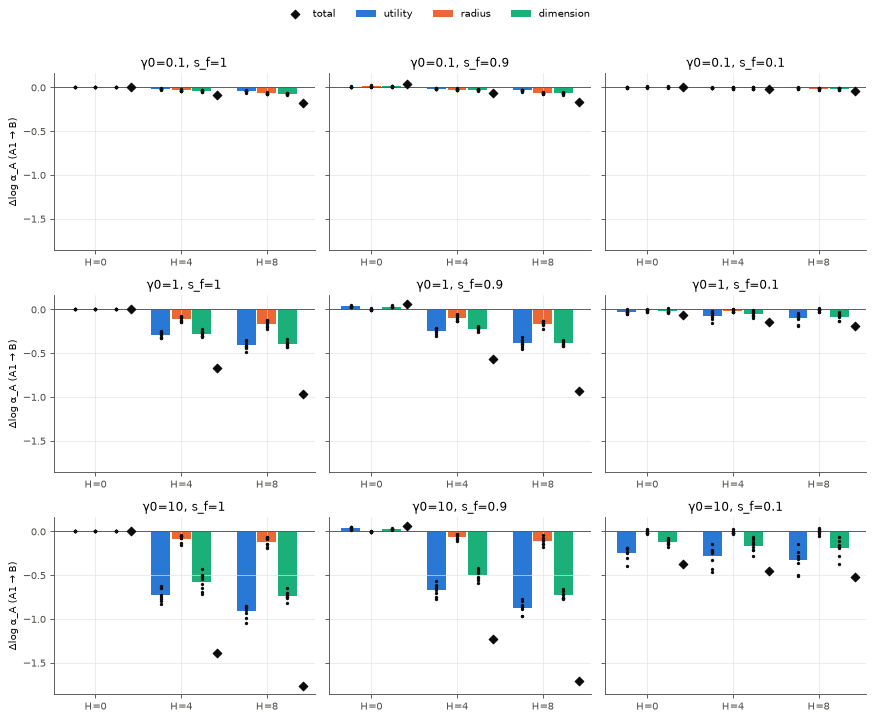

In [18]:
CH = [("utility", BLUE), ("radius", ORANGE), ("dimension", AQUA)]
if HAVE:
    fig, axes = plt.subplots(len(cfg.gammas), len(cfg.s_fs), figsize=(11, 3 * len(cfg.gammas)), sharey=True, squeeze=False)
    for i, g in enumerate(cfg.gammas):
        for j, sf in enumerate(cfg.s_fs):
            ax = axes[i, j]
            for k, h in enumerate(cfg.hammings):
                rs = sel(g, h, sf)
                if not rs: continue
                for ci, (ch, col) in enumerate(CH):
                    v = [r["backward"]["A1_to_B"][ch] for r in rs]; x = k + (ci - 1) * 0.24
                    ax.bar(x, np.mean(v), width=0.22, color=col, label=ch if (i, j, k) == (0, 0, 0) else None)
                    ax.scatter([x] * len(v), v, s=9, color=INK, zorder=3, linewidths=0)
                tot = [r["backward"]["A1_to_B"]["total"] for r in rs]
                ax.scatter([k + 0.42], [np.mean(tot)], marker="D", s=30, color=INK, zorder=4,
                           label="total" if (i, j, k) == (0, 0, 0) else None)
            ax.axhline(0, color=MUTED, linewidth=0.8)
            ax.set_xticks(range(len(cfg.hammings)), [f"H={h}" for h in cfg.hammings])
            ax.set_title(f"γ0={g:g}, s_f={sf:g}")
        axes[i, 0].set_ylabel("Δlog α_A (A1 → B)")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
    plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

**Q2. Behavioural forgetting and relearning.** Test loss on A through A → B → A, seed 0, s_f = 0.9. Each phase is scaled to unit width, because the step counts differ by orders of magnitude across γ₀.

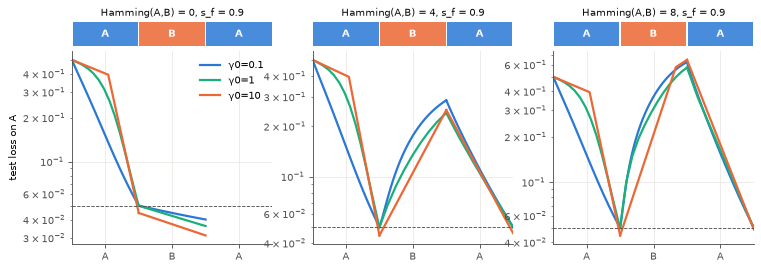

| γ0 | s_f | H | n | forgetting on B, test loss (vs running min) | forgetting on B, test acc (vs running max) | H/P | max |acc forgetting − H/P| over seeds | savings log((1+steps A1)/(1+steps A2)), mean [CI] | savings per seed | raw steps A1 (per seed) | raw steps B | raw steps A2 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 8 | +0.0000 | +0.0000 | 0.0000 | 0.00e+00 | excluded¹ | — | 1630/1673/1975/1828/1769/1601/1892/1806 | 0/0/0/0/0/0/0/0 | 0/0/0/0/0/0/0/0 |
| 0.1 | 1 | 4 | 8 | +0.2740 | +0.2482 | 0.2500 | 7.50e-03 | +0.573 [+0.490, +0.656] | +0.42 +0.69 +0.70 +0.61 +0.54 +0.52 +0.49 +0.62 | 1630/1673/1828/1975/1769/1892/1601/1806 | 1585/1285/1341/1617/1537/1863/1571/1204 | 1076/837/909/1074/1028/1123/985/970 |
| 0.1 | 1 | 8 | 8 | +0.6805 | +0.4992 | 0.5000 | 5.83e-03 | +0.159 [+0.074, +0.244] | +0.09 +0.17 +0.22 +0.33 +0.12 +0.05 +0.25 +0.04 | 1630/1673/1975/1828/1769/1601/1892/1806 | 2063/1788/1802/1505/1851/1919/1741/2106 | 1483/1416/1579/1312/1575/1520/1479/1728 |
| 0.1 | 0.9 | 0 | 8 | -0.0003 | +0.0000 | 0.0000 | 0.00e+00 | +7.478 [+7.416, +7.539] | +7.40 +7.42 +7.59 +7.51 +7.48 +7.38 +7.55 +7.50 | 1630/1673/1975/1828/1769/1601/1892/1806 | 220/236/363/458/581/144/578/452 | 0/0/0/0/0/0/0/0 |
| 0.1 | 0.9 | 4 | 8 | +0.2118 | +0.2340 | 0.2500 | 3.96e-02 | +0.740 [+0.628, +0.851] | +0.45 +0.75 +0.82 +0.81 +0.73 +0.69 +0.75 +0.91 | 1630/1673/1975/1828/1769/1601/1892/1806 | 1593/1428/1532/1364/1421/1461/1687/1120 | 1037/786/867/813/856/799/890/730 |
| 0.1 | 0.9 | 8 | 8 | +0.5273 | +0.4829 | 0.5000 | 4.04e-02 | +0.340 [+0.251, +0.429] | +0.28 +0.38 +0.42 +0.45 +0.34 +0.18 +0.47 +0.21 | 1630/1673/1975/1828/1769/1601/1892/1806 | 1970/1664/1573/1593/1787/1794/1510/2094 | 1237/1146/1302/1171/1255/1335/1187/1458 |
| 0.1 | 0.1 | 0 | 8 | +0.0180 | +0.0072 | 0.0000 | 1.67e-02 | +2.867 [+1.288, +4.447] | +1.75 +2.35 +2.05 +7.51 +2.39 +2.37 +2.20 +2.31 | 1630/1673/1975/1828/1769/1601/1892/1806 | 1621/1311/1473/1368/1367/1381/1492/1480 | 282/158/254/0/161/149/208/178 |
| 0.1 | 0.1 | 4 | 8 | +0.0421 | +0.0208 | 0.2500 | 2.47e-01 | +1.621 [+1.252, +1.989] | +1.52 +1.24 +1.17 +2.55 +1.93 +1.47 +1.62 +1.47 | 1630/1673/1975/1828/1769/1601/1806/1892 | 1787/1500/1799/1591/1378/1369/1520/1574 | 357/483/611/142/256/368/358/433 |
| 0.1 | 0.1 | 8 | 8 | +0.0561 | +0.0214 | 0.5000 | 5.00e-01 | +1.470 [+1.203, +1.737] | +1.59 +1.48 +1.77 +1.84 +0.97 +1.32 +1.70 +1.09 | 1673/1630/1975/1828/1769/1601/1892/1806 | 1770/1509/1416/1524/1923/1654/1561/1759 | 339/369/337/289/672/429/345/604 |
| 1 | 1 | 0 | 8 | +0.0000 | +0.0000 | 0.0000 | 0.00e+00 | excluded¹ | — | 311/304/359/328/328/305/342/342 | 0/0/0/0/0/0/0/0 | 0/0/0/0/0/0/0/0 |
| 1 | 1 | 4 | 8 | +0.2412 | +0.2491 | 0.2500 | 5.00e-03 | +0.859 [+0.766, +0.952] | +0.74 +0.89 +0.99 +0.83 +0.84 +0.81 +0.73 +1.04 | 311/304/359/328/328/305/342/342 | 211/190/202/219/208/227/249/150 | 148/124/133/142/141/135/165/120 |
| 1 | 1 | 8 | 8 | +0.6408 | +0.4999 | 0.5000 | 8.33e-04 | +0.367 [+0.287, +0.448] | +0.32 +0.31 +0.45 +0.51 +0.26 +0.31 +0.49 +0.30 | 311/304/359/328/328/305/342/342 | 303/286/263/232/305/273/258/304 | 225/222/229/197/253/224/210/254 |
| 1 | 0.9 | 0 | 8 | -0.0056 | +0.0000 | 0.0000 | 0.00e+00 | +5.793 [+5.742, +5.843] | +5.74 +5.72 +5.89 +5.80 +5.80 +5.72 +5.84 +5.84 | 311/304/359/328/328/305/342/342 | 26/24/40/45/57/22/52/42 | 0/0/0/0/0/0/0/0 |
| 1 | 0.9 | 4 | 8 | +0.1814 | +0.2376 | 0.2500 | 2.50e-02 | +1.158 [+1.045, +1.272] | +0.92 +1.08 +1.30 +1.10 +1.18 +1.19 +1.13 +1.36 | 311/304/359/328/328/305/342/342 | 203/201/188/211/197/207/213/140 | 123/103/97/108/100/92/110/87 |
| 1 | 0.9 | 8 | 8 | +0.4841 | +0.4859 | 0.5000 | 2.50e-02 | +0.718 [+0.642, +0.794] | +0.67 +0.66 +0.82 +0.79 +0.76 +0.58 +0.81 +0.65 | 311/304/359/328/328/305/342/342 | 271/252/221/215/242/266/225/278 | 159/156/157/148/153/171/151/178 |
| 1 | 0.1 | 0 | 8 | +0.0063 | +0.0018 | 0.0000 | 4.58e-03 | +5.317 [+4.569, +6.064] | +4.13 +5.72 +5.89 +5.80 +5.80 +5.72 +3.64 +5.84 | 311/304/359/328/328/305/342/342 | 187/154/173/169/163/179/178/171 | 4/0/0/0/0/0/8/0 |
| 1 | 0.1 | 4 | 8 | +0.0148 | +0.0048 | 0.2500 | 2.50e-01 | +3.316 [+2.394, +4.238] | +3.66 +2.72 +2.28 +5.80 +3.60 +2.83 +2.84 +2.79 | 311/304/359/328/328/305/342/342 | 193/187/207/180/161/183/186/195 | 7/19/36/0/8/17/19/20 |
| 1 | 0.1 | 8 | 8 | +0.0200 | +0.0032 | 0.5000 | 5.00e-01 | +3.209 [+2.169, +4.249] | +2.61 +5.72 +3.05 +4.41 +2.11 +2.68 +2.95 +2.15 | 311/304/359/328/328/305/342/342 | 181/198/167/184/206/204/169/203 | 22/0/16/3/39/20/17/39 |
| 10 | 1 | 0 | 8 | +0.0000 | +0.0000 | 0.0000 | 0.00e+00 | excluded¹ | — | 46/44/53/47/48/45/50/50 | 0/0/0/0/0/0/0/0 | 0/0/0/0/0/0/0/0 |
| 10 | 1 | 4 | 8 | +0.2530 | +0.2497 | 0.2500 | 2.08e-03 | +0.996 [+0.821, +1.170] | +1.08 +1.10 +1.22 +0.69 +0.71 +1.06 +0.89 +1.22 | 46/44/53/47/48/45/50/50 | 21/20/20/31/34/29/30/15 | 15/14/15/23/23/15/20/14 |
| 10 | 1 | 8 | 8 | +0.6866 | +0.5000 | 0.5000 | 0.00e+00 | +0.423 [+0.282, +0.563] | +0.32 +0.41 +0.59 +0.69 +0.20 +0.43 +0.50 +0.24 | 46/44/53/47/48/45/50/50 | 37/38/29/24/44/32/31/37 | 33/29/29/23/39/29/30/39 |
| 10 | 0.9 | 0 | 8 | -0.0159 | +0.0000 | 0.0000 | 0.00e+00 | +3.888 [+3.837, +3.939] | +3.85 +3.81 +3.99 +3.87 +3.89 +3.83 +3.93 +3.93 | 46/44/53/47/48/45/50/50 | 3/3/4/4/6/2/5/4 | 0/0/0/0/0/0/0/0 |
| 10 | 0.9 | 4 | 8 | +0.2026 | +0.2407 | 0.2500 | 2.50e-02 | +1.483 [+1.388, +1.579] | +1.37 +1.41 +1.59 +1.39 +1.41 +1.63 +1.45 +1.63 | 46/44/53/47/48/45/50/50 | 21/21/19/33/32/26/24/14 | 11/10/10/11/11/8/11/9 |
| 10 | 0.9 | 8 | 8 | +0.5424 | +0.4881 | 0.5000 | 2.96e-02 | +1.081 [+0.975, +1.186] | +1.02 +1.03 +1.28 +1.10 +1.18 +0.88 +1.16 +0.99 | 46/44/53/47/48/45/50/50 | 30/30/23/21/28/32/26/31 | 16/15/14/15/14/18/15/18 |
| 10 | 0.1 | 0 | 8 | +0.0109 | +0.0064 | 0.0000 | 1.42e-02 | +3.006 [+2.786, +3.227] | +2.75 +3.11 +3.30 +3.18 +3.20 +3.14 +2.55 +2.83 | 46/44/53/47/48/45/50/50 | 21/17/20/20/18/22/20/20 | 2/1/1/1/1/1/3/2 |
| 10 | 0.1 | 4 | 8 | +0.0241 | +0.0109 | 0.2500 | 2.50e-01 | +2.632 [+2.413, +2.851] | +3.16 +2.42 +2.38 +2.77 +2.79 +2.44 +2.55 +2.55 | 46/44/53/47/48/45/50/50 | 20/22/27/20/18/23/20/24 | 1/3/4/2/2/3/3/3 |
| 10 | 0.1 | 8 | 8 | +0.0276 | +0.0101 | 0.5000 | 5.00e-01 | +2.791 [+2.344, +3.238] | +2.46 +3.81 +2.89 +3.18 +2.10 +2.73 +2.83 +2.32 | 46/44/53/47/48/45/50/50 | 22/25/20/21/22/28/17/24 | 3/0/2/1/5/2/2/4 |

¹ Identity cell (H0, s_f 1.0): B and A2 take 0 steps, so the savings log ratio is log(1+steps A1) by construction. It is excluded from every savings summary.

accuracy forgetting vs H/P: max deviation over all cells and seeds = 5.00e-01


In [19]:
ACC_DEV = []
if HAVE:
    SF = 0.9 if 0.9 in cfg.s_fs else cfg.s_fs[0]
    fig = plt.figure(figsize=(11, 3.6))
    gs = fig.add_gridspec(2, len(cfg.hammings), height_ratios=[0.12, 1], hspace=0.05)
    for k, h in enumerate(cfg.hammings):
        stream_strip(fig.add_subplot(gs[0, k]), h, SF)
        ax = fig.add_subplot(gs[1, k])
        for g in cfg.gammas:
            rs = sel(g, h, SF)
            r = next((x for x in rs if x["spec"]["seed"] == 0), None)
            if r is None: continue
            for p, ph in enumerate(("A1", "B", "A2")):
                rec = r["trajectory"][ph]; st = np.array([q["step"] for q in rec], float)
                x = p + (st / st.max() if st.max() > 0 else np.zeros_like(st))
                ax.plot(x, [q["A_test_loss"] for q in rec], color=GAMMA_COL[g], label=f"γ0={g:g}" if p == 0 else None)
        ax.axhline(cfg.target_loss, color=MUTED, linewidth=0.8, linestyle="--")
        ax.set_yscale("log"); ax.set_xlim(0, 3); ax.set_xticks([0.5, 1.5, 2.5], ["A", "B", "A"])
        if k == 0: ax.set_ylabel("test loss on A"); ax.legend(frameon=False)
    plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                fl = [r["behaviour"]["forget_B_loss"]["forgetting"] for r in rs]
                fa = [r["behaviour"]["forget_B_acc"]["forgetting"] for r in rs]
                dev = max(abs(x - h / cfg.P) for x in fa); ACC_DEV.append((g, sf, h, dev))
                sv = [r["behaviour"]["savings"] for r in rs]
                stp = lambda p: "/".join(str(r["behaviour"]["steps"][p]) for r in rs)
                ident = IDENTITY(h, sf)
                rows.append([f"{g:g}", f"{sf:g}", h, len(rs), f"{np.mean(fl):+.4f}", f"{np.mean(fa):+.4f}", f"{h / cfg.P:.4f}", f"{dev:.2e}",
                             "excluded¹" if ident else mci(sv), "—" if ident else " ".join(f"{x:+.2f}" for x in sv),
                             stp("A1"), stp("B"), stp("A2")])
    md_table(["γ0", "s_f", "H", "n", "forgetting on B, test loss (vs running min)", "forgetting on B, test acc (vs running max)",
              "H/P", "max |acc forgetting − H/P| over seeds",
              "savings log((1+steps A1)/(1+steps A2)), mean [CI]", "savings per seed", "raw steps A1 (per seed)", "raw steps B", "raw steps A2"], rows)
    display(Markdown("¹ Identity cell (H0, s_f 1.0): B and A2 take 0 steps, so the savings log ratio is "
                     "log(1+steps A1) by construction. It is excluded from every savings summary."))
    print(f"accuracy forgetting vs H/P: max deviation over all cells and seeds = {max(d for *_, d in ACC_DEV):.2e}")

**Q2b. Bottleneck probe: the behavioural counterpart of capacity.** The frozen hidden layer
is projected to `cfg.bottleneck_n` units by a fixed random projection (drawn once per seed),
and a fresh width-n readout is fitted by full-batch GD (μP scaling, lr·s² = lr0/n at every γ₀)
for a fixed `cfg.refit_steps` steps, then scored on A's test points. n was calibrated once on
the init representation at FULL scale so that init accuracy ≈ 0.75, then frozen
(`docs/reference/choices-register.md`). The init column is identical across γ₀.

Secondary: the **full-width refit loss** (fresh readout on all N units, same budget). Its
accuracy is not shown: it saturates (0.998 at init in the 11-09 QUICK run).

In [20]:
RB = ("init", "A1", "B", "A2")
if HAVE:
    print(f"bottleneck width n = {cfg.bottleneck_n}; budget {cfg.refit_steps} steps; checkpoints also at {L.REFIT_CHECKPOINTS}")
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if not rs: continue
        bl = lambda b, m: np.mean([r["bottleneck"][b][m] for r in rs])
        dacc = [r["bottleneck"]["B"]["acc"] - r["bottleneck"]["A1"]["acc"] for r in rs]
        rows.append([f"{g:g}", f"{sf:g}", h]
                    + [f"{bl(b, 'acc'):.3f}" for b in RB] + [mci(dacc)]
                    + [f"{bl(b, 'loss'):.4f}" for b in RB]
                    + [" / ".join(f"{np.mean([r['refit'][b]['loss'] for r in rs]):.4f}" for b in RB)])
    md_table(["γ0", "s_f", "H", "bottleneck test acc: init", "after A", "after B", "after A again",
              "Δ acc A→B, mean [CI]", "bottleneck test loss: init", "after A", "after B", "after A again",
              "full-width refit loss init / A / B / A (secondary)"], rows)

bottleneck width n = 16; budget 2000 steps; checkpoints also at (100, 500)


| γ0 | s_f | H | bottleneck test acc: init | after A | after B | after A again | Δ acc A→B, mean [CI] | bottleneck test loss: init | after A | after B | after A again | full-width refit loss init / A / B / A (secondary) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 0.766 | 0.822 | 0.822 | 0.822 | +0.000 [+0.000, +0.000] | 0.3220 | 0.2671 | 0.2671 | 0.2671 | 0.0821 / 0.0414 / 0.0414 / 0.0414 |
| 0.1 | 1 | 4 | 0.766 | 0.822 | 0.794 | 0.826 | -0.028 [-0.042, -0.015] | 0.3220 | 0.2671 | 0.2951 | 0.2606 | 0.0821 / 0.0414 / 0.0543 / 0.0333 |
| 0.1 | 1 | 8 | 0.766 | 0.822 | 0.785 | 0.827 | -0.036 [-0.054, -0.019] | 0.3220 | 0.2671 | 0.3036 | 0.2619 | 0.0821 / 0.0414 / 0.0707 / 0.0363 |
| 0.1 | 0.9 | 0 | 0.766 | 0.822 | 0.830 | 0.830 | +0.008 [+0.005, +0.011] | 0.3220 | 0.2671 | 0.2592 | 0.2592 | 0.0821 / 0.0414 / 0.0366 / 0.0366 |
| 0.1 | 0.9 | 4 | 0.766 | 0.822 | 0.799 | 0.828 | -0.023 [-0.035, -0.011] | 0.3220 | 0.2671 | 0.2876 | 0.2600 | 0.0821 / 0.0414 / 0.0499 / 0.0333 |
| 0.1 | 0.9 | 8 | 0.766 | 0.822 | 0.795 | 0.826 | -0.027 [-0.043, -0.011] | 0.3220 | 0.2671 | 0.2963 | 0.2627 | 0.0821 / 0.0414 / 0.0672 / 0.0365 |
| 0.1 | 0.1 | 0 | 0.766 | 0.822 | 0.824 | 0.826 | +0.002 [-0.003, +0.006] | 0.3220 | 0.2671 | 0.2655 | 0.2632 | 0.0821 / 0.0414 / 0.0396 / 0.0375 |
| 0.1 | 0.1 | 4 | 0.766 | 0.822 | 0.816 | 0.823 | -0.006 [-0.013, +0.000] | 0.3220 | 0.2671 | 0.2727 | 0.2651 | 0.0821 / 0.0414 / 0.0426 / 0.0372 |
| 0.1 | 0.1 | 8 | 0.766 | 0.822 | 0.812 | 0.821 | -0.010 [-0.015, -0.005] | 0.3220 | 0.2671 | 0.2764 | 0.2670 | 0.0821 / 0.0414 / 0.0452 / 0.0383 |
| 1 | 1 | 0 | 0.766 | 0.979 | 0.979 | 0.979 | +0.000 [+0.000, +0.000] | 0.3220 | 0.1031 | 0.1031 | 0.1031 | 0.0821 / 0.0155 / 0.0155 / 0.0155 |
| 1 | 1 | 4 | 0.766 | 0.979 | 0.871 | 0.974 | -0.108 [-0.147, -0.070] | 0.3220 | 0.1031 | 0.2182 | 0.1027 | 0.0821 / 0.0155 / 0.0399 / 0.0128 |
| 1 | 1 | 8 | 0.766 | 0.979 | 0.808 | 0.979 | -0.171 [-0.235, -0.107] | 0.3220 | 0.1031 | 0.2824 | 0.0985 | 0.0821 / 0.0155 / 0.0615 / 0.0134 |
| 1 | 0.9 | 0 | 0.766 | 0.979 | 0.984 | 0.984 | +0.005 [+0.001, +0.010] | 0.3220 | 0.1031 | 0.0942 | 0.0942 | 0.0821 / 0.0155 / 0.0138 / 0.0138 |
| 1 | 0.9 | 4 | 0.766 | 0.979 | 0.890 | 0.974 | -0.089 [-0.117, -0.060] | 0.3220 | 0.1031 | 0.1907 | 0.1028 | 0.0821 / 0.0155 / 0.0342 / 0.0131 |
| 1 | 0.9 | 8 | 0.766 | 0.979 | 0.827 | 0.978 | -0.152 [-0.204, -0.100] | 0.3220 | 0.1031 | 0.2601 | 0.0995 | 0.0821 / 0.0155 / 0.0577 / 0.0135 |
| 1 | 0.1 | 0 | 0.766 | 0.979 | 0.970 | 0.970 | -0.009 [-0.017, -0.002] | 0.3220 | 0.1031 | 0.1117 | 0.1114 | 0.0821 / 0.0155 / 0.0177 / 0.0175 |
| 1 | 0.1 | 4 | 0.766 | 0.979 | 0.960 | 0.967 | -0.019 [-0.033, -0.005] | 0.3220 | 0.1031 | 0.1236 | 0.1166 | 0.0821 / 0.0155 / 0.0197 / 0.0176 |
| 1 | 0.1 | 8 | 0.766 | 0.979 | 0.965 | 0.971 | -0.014 [-0.023, -0.005] | 0.3220 | 0.1031 | 0.1208 | 0.1134 | 0.0821 / 0.0155 / 0.0210 / 0.0182 |
| 10 | 1 | 0 | 0.766 | 0.999 | 0.999 | 0.999 | +0.000 [+0.000, +0.000] | 0.3220 | 0.0390 | 0.0390 | 0.0390 | 0.0821 / 0.0113 / 0.0113 / 0.0113 |
| 10 | 1 | 4 | 0.766 | 0.999 | 0.919 | 0.996 | -0.080 [-0.106, -0.055] | 0.3220 | 0.0390 | 0.1616 | 0.0448 | 0.0821 / 0.0113 / 0.0258 / 0.0080 |
| 10 | 1 | 8 | 0.766 | 0.999 | 0.833 | 0.998 | -0.166 [-0.221, -0.112] | 0.3220 | 0.0390 | 0.2572 | 0.0422 | 0.0821 / 0.0113 / 0.0434 / 0.0077 |
| 10 | 0.9 | 0 | 0.766 | 0.999 | 0.999 | 0.999 | +0.000 [-0.000, +0.001] | 0.3220 | 0.0390 | 0.0345 | 0.0345 | 0.0821 / 0.0113 / 0.0101 / 0.0101 |
| 10 | 0.9 | 4 | 0.766 | 0.999 | 0.937 | 0.997 | -0.063 [-0.089, -0.036] | 0.3220 | 0.0390 | 0.1360 | 0.0438 | 0.0821 / 0.0113 / 0.0206 / 0.0089 |
| 10 | 0.9 | 8 | 0.766 | 0.999 | 0.827 | 0.998 | -0.172 [-0.206, -0.138] | 0.3220 | 0.0390 | 0.2581 | 0.0415 | 0.0821 / 0.0113 / 0.0380 / 0.0098 |
| 10 | 0.1 | 0 | 0.766 | 0.999 | 0.992 | 0.995 | -0.007 [-0.013, -0.001] | 0.3220 | 0.0390 | 0.0604 | 0.0534 | 0.0821 / 0.0113 / 0.0144 / 0.0130 |
| 10 | 0.1 | 4 | 0.766 | 0.999 | 0.992 | 0.996 | -0.007 [-0.016, +0.002] | 0.3220 | 0.0390 | 0.0686 | 0.0539 | 0.0821 / 0.0113 / 0.0155 / 0.0128 |
| 10 | 0.1 | 8 | 0.766 | 0.999 | 0.994 | 0.997 | -0.005 [-0.008, -0.003] | 0.3220 | 0.0390 | 0.0622 | 0.0504 | 0.0821 / 0.0113 / 0.0165 / 0.0140 |

**Q3. Forward transfer.** Does the geometric change A made on B's manifolds go with behavioural forward transfer? **Specific FT_geo** = Δlog α_{y_B} − mean_k Δlog α_{y\*_k}, init → after A, against K = 4 neutral probes (balanced, s_r(y\*_k, y_A) = 0, fixed per seed). **Specific FT_beh** = FT_beh(cell) − FT_beh(H8, s_f 0.1), paired per seed within γ₀ (warm-start baseline), with FT_beh = log((1+steps fresh)/(1+steps B)). The anchored y\* (s_r = +0.5 to y_A) is kept as one labelled column. Hamming 0 with s_f 1.0 is excluded. Panels are stratified by s_f; nothing is pooled.

| seed | s_r(y* anchored, y_A) | s_r(y*_k neutral, y_A), k = 0..3 |
|---|---|---|
| 0 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 1 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 2 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 3 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 4 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 5 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 6 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 7 | +0.500 | +0.000 +0.000 +0.000 +0.000 |

neutral probes: s_r(y*_k, y_A) = 0 for every k and seed: True


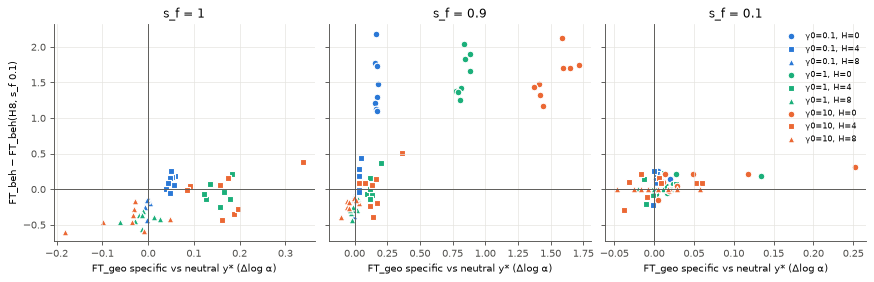

| γ0 | s_f | H | Δlog α_{y_B} total | utility | radius | dimension | mean Δlog α_{y*_k} (neutral) | FT_geo specific (neutral), mean [CI] | FT_geo specific, anchored y* (comparison) | FT_beh, mean [CI] | FT_beh specific (− H8, s_f 0.1), mean [CI] | zero-shot loss on B | raw steps B (per seed) | raw steps fresh B |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 4 | +0.060 | +0.007 | +0.023 | +0.030 | +0.011 | +0.049 [+0.044, +0.055] | +0.003 | +0.259 [+0.210, +0.307] | +0.110 [+0.024, +0.196] | 0.447 | 1585/1285/1341/1617/1537/1863/1571/1204 | 1855/1807/1854/2123/1996/2367/1952/1561 |
| 0.1 | 1 | 8 | +0.009 | -0.003 | +0.005 | +0.008 | +0.011 | -0.001 [-0.004, +0.001] | -0.048 | -0.061 [-0.106, -0.015] | -0.210 [-0.291, -0.128] | 0.826 | 2063/1788/1802/1505/1851/1919/1741/2106 | 2066/1753/1606/1482/1689/1877/1614/1819 |
| 0.1 | 0.9 | 0 | +0.175 | +0.032 | +0.067 | +0.076 | +0.008 | +0.167 [+0.159, +0.174] | +0.131 | +1.636 [+1.319, +1.952] | +1.487 [+1.168, +1.806] | 0.078 | 220/236/363/458/581/144/578/452 | 1512/1563/1826/1810/1987/1469/2067/1974 |
| 0.1 | 0.9 | 4 | +0.046 | +0.004 | +0.019 | +0.024 | +0.008 | +0.038 [+0.033, +0.043] | +0.003 | +0.296 [+0.227, +0.364] | +0.147 [+0.021, +0.273] | 0.443 | 1593/1428/1532/1364/1421/1461/1687/1120 | 1923/1842/2023/1913/2069/1854/2180/1736 |
| 0.1 | 0.9 | 8 | +0.008 | -0.003 | +0.004 | +0.007 | +0.008 | -0.000 [-0.003, +0.002] | -0.036 | -0.004 [-0.060, +0.051] | -0.153 [-0.234, -0.073] | 0.774 | 1970/1664/1573/1593/1787/1794/1510/2094 | 2085/1739/1477/1598/1749/1742/1647/1871 |
| 0.1 | 0.1 | 0 | +0.006 | +0.001 | +0.002 | +0.003 | +0.000 | +0.005 [+0.000, +0.011] | +0.005 | +0.246 [+0.224, +0.268] | +0.097 [+0.017, +0.177] | 0.437 | 1621/1311/1473/1368/1367/1381/1492/1480 | 2125/1751/1876/1750/1740/1707/1849/1909 |
| 0.1 | 0.1 | 4 | +0.001 | -0.000 | +0.001 | +0.000 | +0.000 | +0.001 [-0.001, +0.002] | +0.000 | +0.192 [+0.134, +0.250] | +0.043 [-0.080, +0.166] | 0.513 | 1787/1500/1799/1591/1378/1369/1520/1574 | 2116/1832/1996/1994/1876/1571/1967/1803 |
| 0.1 | 0.1 | 8 | +0.001 | +0.000 | +0.001 | +0.001 | +0.000 | +0.001 [-0.001, +0.003] | +0.001 | +0.149 [+0.075, +0.223] | baseline (0) | 0.539 | 1770/1509/1416/1524/1923/1654/1561/1759 | 2062/1751/1951/1781/2122/1897/1868/1758 |
| 1 | 1 | 4 | +0.259 | +0.028 | +0.075 | +0.156 | +0.109 | +0.149 [+0.128, +0.170] | +0.013 | +0.515 [+0.440, +0.589] | -0.060 [-0.183, +0.063] | 0.433 | 211/190/202/219/208/227/249/150 | 328/323/363/342/363/358/384/297 |
| 1 | 1 | 8 | +0.096 | -0.021 | +0.036 | +0.081 | +0.109 | -0.014 [-0.036, +0.009] | -0.150 | +0.160 [+0.115, +0.205] | -0.414 [-0.479, -0.350] | 0.805 | 303/286/263/232/305/273/258/304 | 355/322/308/289/335/339/322/336 |
| 1 | 0.9 | 0 | +0.918 | +0.310 | +0.192 | +0.416 | +0.087 | +0.831 [+0.798, +0.864] | +0.715 | +2.181 [+1.959, +2.404] | +1.607 [+1.364, +1.850] | 0.078 | 26/24/40/45/57/22/52/42 | 298/294/349/330/367/296/365/358 |
| 1 | 0.9 | 4 | +0.217 | +0.017 | +0.065 | +0.135 | +0.087 | +0.129 [+0.104, +0.155] | +0.013 | +0.585 [+0.490, +0.680] | +0.010 [-0.129, +0.150] | 0.424 | 203/201/188/211/197/207/213/140 | 335/330/358/352/372/351/370/321 |
| 1 | 0.9 | 8 | +0.080 | -0.019 | +0.024 | +0.074 | +0.087 | -0.008 [-0.025, +0.010] | -0.124 | +0.285 [+0.233, +0.337] | -0.290 [-0.357, -0.223] | 0.751 | 271/252/221/215/242/266/225/278 | 359/317/294/299/339/335/331/342 |
| 1 | 0.1 | 0 | +0.037 | +0.001 | +0.014 | +0.022 | +0.002 | +0.036 [-0.000, +0.071] | +0.035 | +0.659 [+0.623, +0.696] | +0.085 [-0.007, +0.177] | 0.430 | 187/154/173/169/163/179/178/171 | 352/324/336/326/328/329/331/335 |
| 1 | 0.1 | 4 | +0.006 | -0.002 | +0.002 | +0.006 | +0.002 | +0.004 [-0.008, +0.016] | +0.004 | +0.593 [+0.536, +0.651] | +0.019 [-0.092, +0.130] | 0.491 | 193/187/207/180/161/183/186/195 | 346/329/347/349/330/306/341/356 |
| 1 | 0.1 | 8 | +0.006 | -0.004 | +0.003 | +0.006 | +0.002 | +0.004 [-0.008, +0.016] | +0.004 | +0.575 [+0.500, +0.650] | baseline (0) | 0.529 | 181/198/167/184/206/204/169/203 | 324/348/343/332/334/345/336/323 |
| 10 | 1 | 4 | +0.535 | +0.009 | +0.131 | +0.395 | +0.361 | +0.174 [+0.109, +0.240] | +0.005 | +0.708 [+0.526, +0.891] | -0.056 [-0.288, +0.177] | 0.435 | 21/20/20/31/34/29/30/15 | 48/47/52/50/54/52/55/44 |
| 10 | 1 | 8 | +0.315 | -0.079 | +0.104 | +0.290 | +0.361 | -0.046 [-0.102, +0.010] | -0.215 | +0.346 [+0.237, +0.456] | -0.417 [-0.540, -0.295] | 0.816 | 37/38/29/24/44/32/31/37 | 51/47/45/42/51/49/48/50 |
| 10 | 0.9 | 0 | +1.823 | +0.678 | +0.200 | +0.945 | +0.300 | +1.523 [+1.416, +1.630] | +1.383 | +2.352 [+2.192, +2.512] | +1.588 [+1.340, +1.836] | 0.075 | 3/3/4/4/6/2/5/4 | 45/44/52/47/54/44/53/52 |
| 10 | 0.9 | 4 | +0.451 | -0.008 | +0.108 | +0.351 | +0.300 | +0.151 [+0.069, +0.232] | +0.010 | +0.774 [+0.580, +0.969] | +0.010 [-0.224, +0.244] | 0.421 | 21/21/19/33/32/26/24/14 | 48/49/52/51/56/52/54/47 |
| 10 | 0.9 | 8 | +0.268 | -0.074 | +0.077 | +0.264 | +0.300 | -0.033 [-0.070, +0.005] | -0.173 | +0.547 [+0.458, +0.635] | -0.217 [-0.286, -0.148] | 0.762 | 30/30/23/21/28/32/26/31 | 52/46/44/43/51/49/50/50 |
| 10 | 0.1 | 0 | +0.055 | -0.025 | +0.025 | +0.055 | -0.007 | +0.062 [-0.009, +0.133] | +0.064 | +0.879 [+0.831, +0.928] | +0.115 [-0.011, +0.242] | 0.440 | 21/17/20/20/18/22/20/20 | 50/47/49/49/48/50/49/49 |
| 10 | 0.1 | 4 | -0.003 | -0.035 | +0.002 | +0.031 | -0.007 | +0.004 [-0.026, +0.034] | +0.006 | +0.803 [+0.697, +0.910] | +0.040 [-0.096, +0.175] | 0.493 | 20/22/27/20/18/23/20/24 | 50/48/50/51/48/46/51/52 |
| 10 | 0.1 | 8 | -0.005 | -0.036 | +0.001 | +0.029 | -0.007 | +0.002 [-0.026, +0.029] | +0.004 | +0.764 [+0.646, +0.882] | baseline (0) | 0.530 | 22/25/20/21/22/28/17/24 | 47/50/50/49/47/51/49/47 |

In [21]:
MARK = dict(zip(cfg.hammings, ["o", "s", "^", "v", "P"]))
BASE_CELL = (8, 0.1)
def ft_beh_spec(r):
    b = [x for x in sel(r["spec"]["gamma"], *BASE_CELL) if x["spec"]["seed"] == r["spec"]["seed"]]
    return r["behaviour"]["FT_beh"] - b[0]["behaviour"]["FT_beh"]
if HAVE:
    srs = sorted({r["spec"]["seed"]: r["relations"] for r in arms}.items())
    md_table(["seed", "s_r(y* anchored, y_A)", "s_r(y*_k neutral, y_A), k = 0..3"],
             [[s, f"{rel['s_r_ystar_A']:+.3f}", " ".join(f"{v:+.3f}" for v in rel["s_r_ystar_neutral_A"].values())] for s, rel in srs])
    print("neutral probes: s_r(y*_k, y_A) = 0 for every k and seed:",
          all(v == 0.0 for r in arms for v in r["relations"]["s_r_ystar_neutral_A"].values()))
if HAVE:
    fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.6), sharey=True)
    for ax, sf in zip(axes, cfg.s_fs):
        for g in cfg.gammas:
            for h in cfg.hammings:
                if h == 0 and sf == 1.0: continue
                rs = sel(g, h, sf)
                ax.scatter([r["forward"]["specific"] for r in rs], [ft_beh_spec(r) for r in rs],
                           color=GAMMA_COL[g], marker=MARK[h], s=36, edgecolors="white", linewidths=1,
                           label=f"γ0={g:g}, H={h}" if sf == cfg.s_fs[-1] else None)
        ax.axhline(0, color=MUTED, linewidth=0.8); ax.axvline(0, color=MUTED, linewidth=0.8)
        ax.set_title(f"s_f = {sf:g}"); ax.set_xlabel("FT_geo specific vs neutral y* (Δlog α)")
    axes[0].set_ylabel("FT_beh − FT_beh(H8, s_f 0.1)"); axes[-1].legend(frameon=False, fontsize=7, loc="best"); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs or (h == 0 and sf == 1.0): continue
                f = lambda k: np.mean([r["forward"]["total"][k] for r in rs])
                rows.append([f"{g:g}", f"{sf:g}", h, f"{f('total'):+.3f}", f"{f('utility'):+.3f}", f"{f('radius'):+.3f}",
                             f"{f('dimension'):+.3f}", f"{np.mean([r['forward']['ystar_neutral']['mean'] for r in rs]):+.3f}",
                             mci([r['forward']['specific'] for r in rs]),
                             f"{np.mean([r['forward']['specific_anchored'] for r in rs]):+.3f}",
                             mci([r['behaviour']['FT_beh'] for r in rs]),
                             "baseline (0)" if (h, sf) == BASE_CELL else mci([ft_beh_spec(r) for r in rs]),
                             f"{np.mean([r['behaviour']['first_loss']['B'] for r in rs]):.3f}",
                             "/".join(str(r["behaviour"]["steps"]["B"]) for r in rs),
                             "/".join(str(r["behaviour"]["steps"]["freshB"]) for r in rs)])
    md_table(["γ0", "s_f", "H", "Δlog α_{y_B} total", "utility", "radius", "dimension", "mean Δlog α_{y*_k} (neutral)",
              "FT_geo specific (neutral), mean [CI]", "FT_geo specific, anchored y* (comparison)", "FT_beh, mean [CI]",
              "FT_beh specific (− H8, s_f 0.1), mean [CI]",
              "zero-shot loss on B", "raw steps B (per seed)", "raw steps fresh B"], rows)

**Q4. Richness by phase.** Means over cells and seeds for each γ₀. ΔK and ΔK_u are relative to init, on A's fixed probe set. r_t is the weight change within a phase.

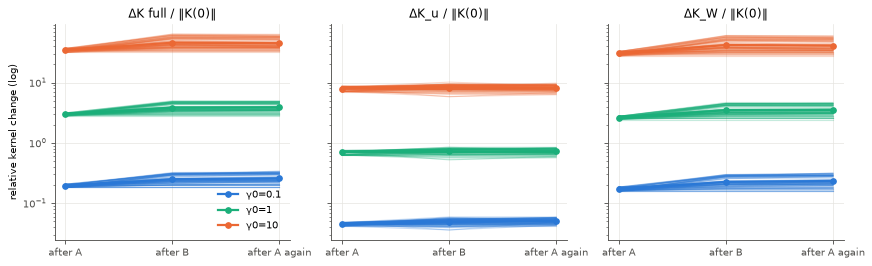

| γ0 | after | weight change from init | r_t (this phase) | ΔK full | ΔK_u | ΔK_W | ‖K_W‖/‖K‖ | CKA(K, y_A y_Aᵀ) | CKA(K_B, y_B y_Bᵀ) |
|---|---|---|---|---|---|---|---|---|---|
| 0.1 | A1 | 0.0202 | 0.0202 | 0.193 | 0.0454 | 0.17 | 0.152 | +0.268 | +0.213 |
| 0.1 | B | 0.033 | 0.0267 | 0.25 | 0.049 | 0.226 | 0.195 | +0.245 | +0.256 |
| 0.1 | A2 | 0.0311 | 0.0135 | 0.259 | 0.0506 | 0.234 | 0.200 | +0.266 | +0.238 |
| 1 | A1 | 0.154 | 0.154 | 2.98 | 0.694 | 2.62 | 0.717 | +0.350 | +0.235 |
| 1 | B | 0.203 | 0.145 | 3.85 | 0.722 | 3.49 | 0.772 | +0.282 | +0.310 |
| 1 | A2 | 0.195 | 0.0665 | 3.88 | 0.723 | 3.52 | 0.773 | +0.321 | +0.272 |
| 10 | A1 | 0.618 | 0.618 | 34.3 | 7.92 | 30.4 | 0.870 | +0.352 | +0.233 |
| 10 | B | 0.747 | 0.41 | 45.7 | 8.21 | 41.8 | 0.899 | +0.276 | +0.310 |
| 10 | A2 | 0.741 | 0.193 | 44.9 | 8.14 | 41 | 0.898 | +0.319 | +0.270 |

**Phase-to-phase kernel change** (from the previous boundary: ‖·_now − ·_prev‖ / ‖K_prev‖_F; alignment = CKA(K_prev, K_now), 1 = same direction). Lines: mean over s_f and seeds per γ₀ × H, identity cell excluded (0 / 1 by construction). Table: per cell, mean [95% CI].

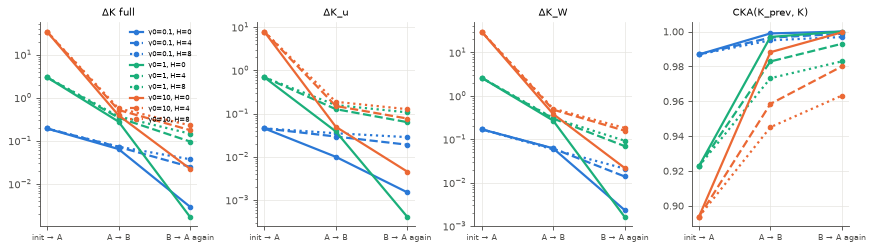

| γ0 | s_f | H | transition | ΔK full | ΔK_u | ΔK_W | CKA(K_prev, K) |
|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | A → B | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 0.1 | 1 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 0.1 | 1 | 4 | A → B | +0.0537 [+0.0472, +0.0602] | +0.0379 [+0.0354, +0.0404] | +0.0352 [+0.0266, +0.0437] | +0.9956 [+0.9952, +0.9960] |
| 0.1 | 1 | 4 | B → A again | +0.0318 [+0.0296, +0.0340] | +0.0272 [+0.0253, +0.0292] | +0.0154 [+0.0131, +0.0177] | +0.9978 [+0.9975, +0.9981] |
| 0.1 | 1 | 8 | A → B | +0.0563 [+0.0500, +0.0627] | +0.0459 [+0.0440, +0.0477] | +0.0294 [+0.0222, +0.0366] | +0.9933 [+0.9925, +0.9942] |
| 0.1 | 1 | 8 | B → A again | +0.0473 [+0.0462, +0.0484] | +0.0416 [+0.0403, +0.0428] | +0.0220 [+0.0204, +0.0236] | +0.9945 [+0.9942, +0.9949] |
| 0.1 | 0.9 | 0 | A → B | +0.0294 [+0.0184, +0.0404] | +0.0068 [+0.0044, +0.0093] | +0.0260 [+0.0163, +0.0358] | +0.9998 [+0.9997, +0.9999] |
| 0.1 | 0.9 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 0.1 | 0.9 | 4 | A → B | +0.0626 [+0.0572, +0.0679] | +0.0345 [+0.0332, +0.0358] | +0.0497 [+0.0426, +0.0568] | +0.9963 [+0.9961, +0.9965] |
| 0.1 | 0.9 | 4 | B → A again | +0.0274 [+0.0255, +0.0292] | +0.0229 [+0.0216, +0.0241] | +0.0138 [+0.0116, +0.0159] | +0.9985 [+0.9983, +0.9987] |
| 0.1 | 0.9 | 8 | A → B | +0.0619 [+0.0540, +0.0698] | +0.0413 [+0.0389, +0.0437] | +0.0439 [+0.0358, +0.0521] | +0.9943 [+0.9935, +0.9950] |
| 0.1 | 0.9 | 8 | B → A again | +0.0447 [+0.0424, +0.0471] | +0.0353 [+0.0335, +0.0371] | +0.0250 [+0.0205, +0.0294] | +0.9962 [+0.9959, +0.9965] |
| 0.1 | 0.1 | 0 | A → B | +0.0995 [+0.0926, +0.1064] | +0.0131 [+0.0117, +0.0145] | +0.0979 [+0.0909, +0.1049] | +0.9980 [+0.9977, +0.9983] |
| 0.1 | 0.1 | 0 | B → A again | +0.0059 [+0.0037, +0.0080] | +0.0030 [+0.0017, +0.0043] | +0.0047 [+0.0030, +0.0064] | +0.9999 [+0.9999, +1.0000] |
| 0.1 | 0.1 | 4 | A → B | +0.1001 [+0.0914, +0.1088] | +0.0158 [+0.0152, +0.0164] | +0.0993 [+0.0915, +0.1071] | +0.9976 [+0.9974, +0.9978] |
| 0.1 | 0.1 | 4 | B → A again | +0.0155 [+0.0096, +0.0213] | +0.0070 [+0.0048, +0.0091] | +0.0125 [+0.0077, +0.0174] | +0.9998 [+0.9997, +0.9999] |
| 0.1 | 0.1 | 8 | A → B | +0.1014 [+0.0979, +0.1048] | +0.0178 [+0.0155, +0.0202] | +0.1016 [+0.0983, +0.1050] | +0.9972 [+0.9969, +0.9976] |
| 0.1 | 0.1 | 8 | B → A again | +0.0201 [+0.0112, +0.0290] | +0.0085 [+0.0054, +0.0117] | +0.0163 [+0.0088, +0.0238] | +0.9997 [+0.9996, +0.9999] |
| 1 | 1 | 0 | A → B | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 1 | 1 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 1 | 1 | 4 | A → B | +0.2624 [+0.2356, +0.2892] | +0.1658 [+0.1559, +0.1757] | +0.1842 [+0.1583, +0.2101] | +0.9742 [+0.9709, +0.9776] |
| 1 | 1 | 4 | B → A again | +0.1506 [+0.1439, +0.1573] | +0.1041 [+0.1006, +0.1076] | +0.1059 [+0.0970, +0.1149] | +0.9868 [+0.9855, +0.9881] |
| 1 | 1 | 8 | A → B | +0.2952 [+0.2744, +0.3161] | +0.2122 [+0.2011, +0.2233] | +0.1780 [+0.1557, +0.2004] | +0.9590 [+0.9546, +0.9634] |
| 1 | 1 | 8 | B → A again | +0.2262 [+0.2154, +0.2370] | +0.1779 [+0.1691, +0.1867] | +0.1310 [+0.1215, +0.1405] | +0.9676 [+0.9643, +0.9709] |
| 1 | 0.9 | 0 | A → B | +0.1114 [+0.0842, +0.1387] | +0.0240 [+0.0184, +0.0295] | +0.1000 [+0.0753, +0.1246] | +0.9996 [+0.9994, +0.9997] |
| 1 | 0.9 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 1 | 0.9 | 4 | A → B | +0.2958 [+0.2699, +0.3217] | +0.1502 [+0.1394, +0.1609] | +0.2467 [+0.2201, +0.2734] | +0.9819 [+0.9790, +0.9848] |
| 1 | 0.9 | 4 | B → A again | +0.1133 [+0.1061, +0.1206] | +0.0779 [+0.0727, +0.0831] | +0.0797 [+0.0713, +0.0882] | +0.9925 [+0.9914, +0.9937] |
| 1 | 0.9 | 8 | A → B | +0.3206 [+0.2960, +0.3451] | +0.1889 [+0.1760, +0.2019] | +0.2515 [+0.2218, +0.2813] | +0.9698 [+0.9659, +0.9737] |
| 1 | 0.9 | 8 | B → A again | +0.1819 [+0.1694, +0.1944] | +0.1316 [+0.1211, +0.1420] | +0.1185 [+0.1073, +0.1297] | +0.9817 [+0.9792, +0.9842] |
| 1 | 0.1 | 0 | A → B | +0.4465 [+0.4183, +0.4746] | +0.0531 [+0.0455, +0.0606] | +0.4405 [+0.4120, +0.4689] | +0.9942 [+0.9935, +0.9949] |
| 1 | 0.1 | 0 | B → A again | +0.0034 [-0.0019, +0.0088] | +0.0008 [-0.0005, +0.0022] | +0.0032 [-0.0018, +0.0083] | +1.0000 [+0.9999, +1.0000] |
| 1 | 0.1 | 4 | A → B | +0.4743 [+0.4577, +0.4910] | +0.0634 [+0.0579, +0.0690] | +0.4733 [+0.4572, +0.4894] | +0.9923 [+0.9908, +0.9938] |
| 1 | 0.1 | 4 | B → A again | +0.0249 [+0.0143, +0.0354] | +0.0077 [+0.0040, +0.0114] | +0.0233 [+0.0130, +0.0335] | +0.9996 [+0.9993, +0.9999] |
| 1 | 0.1 | 8 | A → B | +0.4921 [+0.4702, +0.5139] | +0.0703 [+0.0605, +0.0800] | +0.4960 [+0.4734, +0.5186] | +0.9908 [+0.9892, +0.9925] |
| 1 | 0.1 | 8 | B → A again | +0.0307 [+0.0130, +0.0484] | +0.0100 [+0.0033, +0.0167] | +0.0285 [+0.0123, +0.0448] | +0.9994 [+0.9989, +0.9999] |
| 10 | 1 | 0 | A → B | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 10 | 1 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 10 | 1 | 4 | A → B | +0.4107 [+0.3432, +0.4783] | +0.1922 [+0.1772, +0.2071] | +0.3379 [+0.2742, +0.4016] | +0.9410 [+0.9276, +0.9545] |
| 10 | 1 | 4 | B → A again | +0.2699 [+0.2569, +0.2829] | +0.1224 [+0.1171, +0.1277] | +0.2351 [+0.2193, +0.2508] | +0.9622 [+0.9582, +0.9662] |
| 10 | 1 | 8 | A → B | +0.4398 [+0.3959, +0.4838] | +0.2492 [+0.2332, +0.2652] | +0.3328 [+0.2843, +0.3813] | +0.9212 [+0.9134, +0.9291] |
| 10 | 1 | 8 | B → A again | +0.3576 [+0.3451, +0.3702] | +0.2126 [+0.1986, +0.2265] | +0.2713 [+0.2538, +0.2889] | +0.9303 [+0.9246, +0.9359] |
| 10 | 0.9 | 0 | A → B | +0.1356 [+0.1046, +0.1666] | +0.0277 [+0.0215, +0.0339] | +0.1241 [+0.0956, +0.1527] | +0.9988 [+0.9984, +0.9993] |
| 10 | 0.9 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 10 | 0.9 | 4 | A → B | +0.4439 [+0.3814, +0.5065] | +0.1769 [+0.1614, +0.1924] | +0.4007 [+0.3463, +0.4551] | +0.9590 [+0.9491, +0.9690] |
| 10 | 0.9 | 4 | B → A again | +0.1964 [+0.1754, +0.2174] | +0.0926 [+0.0866, +0.0986] | +0.1741 [+0.1542, +0.1939] | +0.9798 [+0.9755, +0.9840] |
| 10 | 0.9 | 8 | A → B | +0.4843 [+0.4249, +0.5438] | +0.2248 [+0.2067, +0.2429] | +0.4167 [+0.3512, +0.4822] | +0.9419 [+0.9359, +0.9480] |
| 10 | 0.9 | 8 | B → A again | +0.2719 [+0.2543, +0.2896] | +0.1521 [+0.1362, +0.1680] | +0.2222 [+0.2130, +0.2315] | +0.9615 [+0.9557, +0.9672] |
| 10 | 0.1 | 0 | A → B | +0.6467 [+0.5897, +0.7037] | +0.0712 [+0.0619, +0.0805] | +0.6423 [+0.5830, +0.7016] | +0.9774 [+0.9724, +0.9824] |
| 10 | 0.1 | 0 | B → A again | +0.0449 [+0.0304, +0.0594] | +0.0090 [+0.0055, +0.0125] | +0.0436 [+0.0295, +0.0578] | +0.9991 [+0.9985, +0.9997] |
| 10 | 0.1 | 4 | A → B | +0.7059 [+0.6607, +0.7512] | +0.0795 [+0.0710, +0.0879] | +0.7071 [+0.6585, +0.7558] | +0.9753 [+0.9715, +0.9791] |
| 10 | 0.1 | 4 | B → A again | +0.0649 [+0.0526, +0.0771] | +0.0149 [+0.0122, +0.0175] | +0.0636 [+0.0502, +0.0769] | +0.9980 [+0.9972, +0.9989] |
| 10 | 0.1 | 8 | A → B | +0.7719 [+0.7102, +0.8336] | +0.0876 [+0.0756, +0.0995] | +0.7775 [+0.7135, +0.8416] | +0.9720 [+0.9669, +0.9772] |
| 10 | 0.1 | 8 | B → A again | +0.0549 [+0.0267, +0.0830] | +0.0140 [+0.0061, +0.0218] | +0.0545 [+0.0259, +0.0832] | +0.9981 [+0.9964, +0.9998] |

In [22]:
if HAVE:
    PH = ("A1", "B", "A2")
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
    for ax, (k, lab) in zip(axes, [("dK_full", "ΔK full"), ("dK_u", "ΔK_u"), ("dK_W", "ΔK_W")]):
        for g in cfg.gammas:
            rs = sel(g)
            per = np.array([[r["richness"][ph][k] for ph in PH] for r in rs])
            for row in per:
                ax.plot(range(3), row, color=GAMMA_COL[g], alpha=0.25, linewidth=1)
            ax.plot(range(3), per.mean(0), color=GAMMA_COL[g], marker="o", markersize=5, label=f"γ0={g:g}")
        ax.set_yscale("log"); ax.set_xticks(range(3), ["after A", "after B", "after A again"]); ax.set_title(f"{lab} / ‖K(0)‖")
    axes[0].set_ylabel("relative kernel change (log)"); axes[0].legend(frameon=False); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        rs = sel(g)
        for ph in PH:
            m = lambda k: np.mean([r["richness"][ph][k] for r in rs])
            rows.append([f"{g:g}", ph, f"{m('weight_change'):.3g}", f"{np.mean([r['richness']['r_t'][ph] for r in rs]):.3g}",
                         f"{m('dK_full'):.3g}", f"{m('dK_u'):.3g}", f"{m('dK_W'):.3g}", f"{m('KW_share'):.3f}",
                         f"{m('cka_K_yA'):+.3f}", f"{m('cka_K_yB'):+.3f}"])
    md_table(["γ0", "after", "weight change from init", "r_t (this phase)", "ΔK full", "ΔK_u", "ΔK_W", "‖K_W‖/‖K‖",
              "CKA(K, y_A y_Aᵀ)", "CKA(K_B, y_B y_Bᵀ)"], rows)
    display(Markdown("**Phase-to-phase kernel change** (from the previous boundary: ‖·_now − ·_prev‖ / ‖K_prev‖_F; "
                     "alignment = CKA(K_prev, K_now), 1 = same direction). Lines: mean over s_f and seeds per γ₀ × H, "
                     "identity cell excluded (0 / 1 by construction). Table: per cell, mean [95% CI]."))
    TR = (("A1", "init → A"), ("B", "A → B"), ("A2", "B → A again"))
    fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
    for ax, (k, lab) in zip(axes, [("dK_full_step", "ΔK full"), ("dK_u_step", "ΔK_u"), ("dK_W_step", "ΔK_W"), ("align_step", "CKA(K_prev, K)")]):
        for g in cfg.gammas:
            for hi, h in enumerate(cfg.hammings):
                rs = [r for r in sel(g, h) if not IDENTITY(h, r["spec"]["s_f"])]
                if rs: ax.plot(range(3), [np.mean([r["richness"][ph][k] for r in rs]) for ph, _ in TR], color=GAMMA_COL[g],
                               linestyle=["-", "--", ":", "-."][hi], marker="o", markersize=4,
                               label=f"γ0={g:g}, H={h}" if k == "dK_full_step" else None)
        if k != "align_step": ax.set_yscale("log")
        ax.set_xticks(range(3), [t for _, t in TR], fontsize=7); ax.set_title(lab, fontsize=9)
    axes[0].legend(frameon=False, fontsize=6); plt.tight_layout(); plt.show()
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if not rs: continue
        for ph, lab in TR[1:]:
            rows.append([f"{g:g}", f"{sf:g}", h, lab] + [mci([r["richness"][ph][k] for r in rs], 4) for k in
                                                         ("dK_full_step", "dK_u_step", "dK_W_step", "align_step")])
    md_table(["γ0", "s_f", "H", "transition", "ΔK full", "ΔK_u", "ΔK_W", "CKA(K_prev, K)"], rows)

**Q5. Centre correlation ρ_c on A's manifolds (signed, normalised), by boundary.** The `glue`-convention value is in a separate table only: it depends on the anchor norm and is not a direction measure.

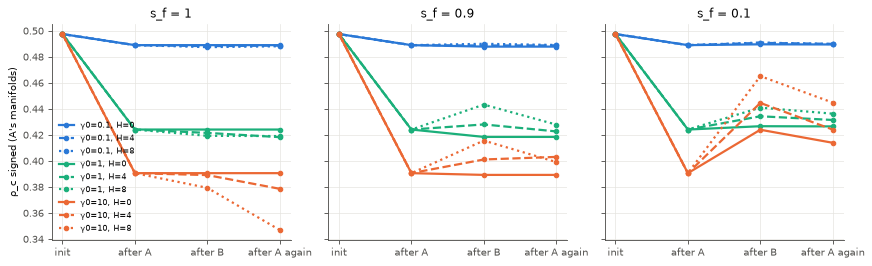

| γ0 | s_f | H | ρ_c signed: init | after A | after B | after A again |
|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | +0.497 [+0.491, +0.504] | +0.489 [+0.482, +0.495] | +0.489 [+0.482, +0.495] | +0.489 [+0.482, +0.495] |
| 0.1 | 1 | 4 | +0.497 [+0.491, +0.504] | +0.489 [+0.482, +0.495] | +0.488 [+0.482, +0.494] | +0.489 [+0.482, +0.495] |
| 0.1 | 1 | 8 | +0.497 [+0.491, +0.504] | +0.489 [+0.482, +0.495] | +0.487 [+0.481, +0.493] | +0.488 [+0.482, +0.495] |
| 0.1 | 0.9 | 0 | +0.497 [+0.491, +0.504] | +0.489 [+0.482, +0.495] | +0.488 [+0.481, +0.494] | +0.488 [+0.481, +0.494] |
| 0.1 | 0.9 | 4 | +0.497 [+0.491, +0.504] | +0.489 [+0.482, +0.495] | +0.489 [+0.483, +0.494] | +0.489 [+0.483, +0.495] |
| 0.1 | 0.9 | 8 | +0.497 [+0.491, +0.504] | +0.489 [+0.482, +0.495] | +0.490 [+0.484, +0.496] | +0.489 [+0.483, +0.496] |
| 0.1 | 0.1 | 0 | +0.497 [+0.491, +0.504] | +0.489 [+0.482, +0.495] | +0.490 [+0.483, +0.496] | +0.489 [+0.483, +0.495] |
| 0.1 | 0.1 | 4 | +0.497 [+0.491, +0.504] | +0.489 [+0.482, +0.495] | +0.491 [+0.484, +0.497] | +0.490 [+0.484, +0.496] |
| 0.1 | 0.1 | 8 | +0.497 [+0.491, +0.504] | +0.489 [+0.482, +0.495] | +0.491 [+0.485, +0.497] | +0.490 [+0.483, +0.496] |
| 1 | 1 | 0 | +0.497 [+0.491, +0.504] | +0.424 [+0.416, +0.432] | +0.424 [+0.416, +0.432] | +0.424 [+0.416, +0.432] |
| 1 | 1 | 4 | +0.497 [+0.491, +0.504] | +0.424 [+0.416, +0.432] | +0.421 [+0.411, +0.432] | +0.418 [+0.409, +0.427] |
| 1 | 1 | 8 | +0.497 [+0.491, +0.504] | +0.424 [+0.416, +0.432] | +0.419 [+0.411, +0.427] | +0.419 [+0.410, +0.428] |
| 1 | 0.9 | 0 | +0.497 [+0.491, +0.504] | +0.424 [+0.416, +0.432] | +0.418 [+0.409, +0.428] | +0.418 [+0.409, +0.428] |
| 1 | 0.9 | 4 | +0.497 [+0.491, +0.504] | +0.424 [+0.416, +0.432] | +0.428 [+0.420, +0.436] | +0.423 [+0.415, +0.431] |
| 1 | 0.9 | 8 | +0.497 [+0.491, +0.504] | +0.424 [+0.416, +0.432] | +0.443 [+0.437, +0.450] | +0.428 [+0.420, +0.436] |
| 1 | 0.1 | 0 | +0.497 [+0.491, +0.504] | +0.424 [+0.416, +0.432] | +0.427 [+0.420, +0.434] | +0.426 [+0.419, +0.433] |
| 1 | 0.1 | 4 | +0.497 [+0.491, +0.504] | +0.424 [+0.416, +0.432] | +0.434 [+0.426, +0.442] | +0.431 [+0.424, +0.439] |
| 1 | 0.1 | 8 | +0.497 [+0.491, +0.504] | +0.424 [+0.416, +0.432] | +0.441 [+0.432, +0.450] | +0.436 [+0.427, +0.445] |
| 10 | 1 | 0 | +0.497 [+0.491, +0.504] | +0.391 [+0.376, +0.405] | +0.391 [+0.376, +0.405] | +0.391 [+0.376, +0.405] |
| 10 | 1 | 4 | +0.497 [+0.491, +0.504] | +0.391 [+0.376, +0.405] | +0.389 [+0.360, +0.418] | +0.379 [+0.359, +0.398] |
| 10 | 1 | 8 | +0.497 [+0.491, +0.504] | +0.391 [+0.376, +0.405] | +0.379 [+0.359, +0.400] | +0.347 [+0.331, +0.363] |
| 10 | 0.9 | 0 | +0.497 [+0.491, +0.504] | +0.391 [+0.376, +0.405] | +0.389 [+0.374, +0.404] | +0.389 [+0.374, +0.404] |
| 10 | 0.9 | 4 | +0.497 [+0.491, +0.504] | +0.391 [+0.376, +0.405] | +0.401 [+0.377, +0.425] | +0.403 [+0.382, +0.424] |
| 10 | 0.9 | 8 | +0.497 [+0.491, +0.504] | +0.391 [+0.376, +0.405] | +0.416 [+0.396, +0.435] | +0.399 [+0.392, +0.407] |
| 10 | 0.1 | 0 | +0.497 [+0.491, +0.504] | +0.391 [+0.376, +0.405] | +0.424 [+0.399, +0.448] | +0.414 [+0.389, +0.439] |
| 10 | 0.1 | 4 | +0.497 [+0.491, +0.504] | +0.391 [+0.376, +0.405] | +0.445 [+0.423, +0.466] | +0.424 [+0.405, +0.443] |
| 10 | 0.1 | 8 | +0.497 [+0.491, +0.504] | +0.391 [+0.376, +0.405] | +0.465 [+0.442, +0.488] | +0.445 [+0.422, +0.468] |

**ρ_c (glue convention): anchor-norm dependent, not a direction measure.** Table only; not used in any figure or reading.

| γ0 | s_f | H | ρ_c glue: init | after A | after B | after A again |
|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 0.594 | 0.553 | 0.553 | 0.553 |
| 0.1 | 1 | 4 | 0.594 | 0.553 | 0.579 | 0.544 |
| 0.1 | 1 | 8 | 0.594 | 0.553 | 0.603 | 0.545 |
| 0.1 | 0.9 | 0 | 0.594 | 0.553 | 0.546 | 0.546 |
| 0.1 | 0.9 | 4 | 0.594 | 0.553 | 0.573 | 0.546 |
| 0.1 | 0.9 | 8 | 0.594 | 0.553 | 0.597 | 0.548 |
| 0.1 | 0.1 | 0 | 0.594 | 0.553 | 0.549 | 0.546 |
| 0.1 | 0.1 | 4 | 0.594 | 0.553 | 0.557 | 0.549 |
| 0.1 | 0.1 | 8 | 0.594 | 0.553 | 0.564 | 0.553 |
| 1 | 1 | 0 | 0.594 | 0.306 | 0.306 | 0.306 |
| 1 | 1 | 4 | 0.594 | 0.306 | 0.611 | 0.285 |
| 1 | 1 | 8 | 0.594 | 0.306 | 0.839 | 0.285 |
| 1 | 0.9 | 0 | 0.594 | 0.306 | 0.289 | 0.289 |
| 1 | 0.9 | 4 | 0.594 | 0.306 | 0.537 | 0.303 |
| 1 | 0.9 | 8 | 0.594 | 0.306 | 0.788 | 0.319 |
| 1 | 0.1 | 0 | 0.594 | 0.306 | 0.326 | 0.326 |
| 1 | 0.1 | 4 | 0.594 | 0.306 | 0.355 | 0.34 |
| 1 | 0.1 | 8 | 0.594 | 0.306 | 0.39 | 0.365 |
| 10 | 1 | 0 | 0.594 | 0.224 | 0.224 | 0.224 |
| 10 | 1 | 4 | 0.594 | 0.224 | 2.16 | 0.231 |
| 10 | 1 | 8 | 0.594 | 0.224 | 3.78 | 0.23 |
| 10 | 0.9 | 0 | 0.594 | 0.224 | 0.229 | 0.229 |
| 10 | 0.9 | 4 | 0.594 | 0.224 | 1.65 | 0.293 |
| 10 | 0.9 | 8 | 0.594 | 0.224 | 3.32 | 0.293 |
| 10 | 0.1 | 0 | 0.594 | 0.224 | 0.42 | 0.36 |
| 10 | 0.1 | 4 | 0.594 | 0.224 | 0.524 | 0.372 |
| 10 | 0.1 | 8 | 0.594 | 0.224 | 0.598 | 0.426 |

In [23]:
BND = ("A@init", "A@A1", "A@B", "A@A2")
LSTYLE = dict(zip(cfg.hammings, ["-", "--", ":", "-."]))
if HAVE:
    fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.4), sharey=True)
    for ax, sf in zip(axes, cfg.s_fs):
        for g in cfg.gammas:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                ax.plot(range(4), [np.mean([r["geometry"][b]["rho_c_signed"] for r in rs]) for b in BND],
                        color=GAMMA_COL[g], linestyle=LSTYLE[h], marker="o", markersize=4,
                        label=f"γ0={g:g}, H={h}" if sf == cfg.s_fs[0] else None)
        ax.set_xticks(range(4), ["init", "after A", "after B", "after A again"]); ax.set_title(f"s_f = {sf:g}")
    axes[0].set_ylabel("ρ_c signed (A's manifolds)"); axes[0].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                rows.append([f"{g:g}", f"{sf:g}", h] + [mci([r["geometry"][b]["rho_c_signed"] for r in rs]) for b in BND])
    md_table(["γ0", "s_f", "H", "ρ_c signed: init", "after A", "after B", "after A again"], rows)
    display(Markdown("**ρ_c (glue convention): anchor-norm dependent, not a direction measure.** Table only; not used in any figure or reading."))
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if rs: rows.append([f"{g:g}", f"{sf:g}", h] + [f"{np.mean([r['geometry'][b]['rho_c_glue'] for r in rs]):.3g}" for b in BND])
    md_table(["γ0", "s_f", "H", "ρ_c glue: init", "after A", "after B", "after A again"], rows)

## 7. Expectation readings

Each expectation is quoted verbatim from the cell written before the run and read by
the rule fixed there.

In [24]:
EXP = {1: "forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1",
       2: "at γ0 = 10, the utility channel carries most of Δlog α_A",
       3: "Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain)",
       4: "Hamming 4 and 8 are similar (cliff, not dose)",
       5: "K_u change separates γ0 more cleanly than the full NTK change"}
G_LO, G_HI = cfg.gammas[0], cfg.gammas[-1]   # the 11-08 expectations compare the ends
d_AB = lambda r: r["backward"]["A1_to_B"]
def by_seed(g, h, sf, f=lambda r: d_AB(r)["total"]):
    return {r["spec"]["seed"]: f(r) for r in sel(g, h, sf)}
def fmt(rv): return f"{rv['mean']:+.4f} [{rv['lo']:+.4f}, {rv['hi']:+.4f}] n={rv['n']}"
READ = []
if HAVE:
    for sf in cfg.s_fs:                                   # 1
        a, b = by_seed(G_HI, 8, sf), by_seed(G_LO, 8, sf)
        d = [a[s] - b[s] for s in sorted(set(a) & set(b))]
        fl = max(FL.values()); rv = resolve(d, fl)
        v = "held" if rv["sign"] < 0 else "not held" if rv["sign"] > 0 else "unresolved at floor"
        READ.append([1, f"s_f={sf:g}", f"d = Δ(γ0={G_HI:g}) − Δ(γ0={G_LO:g}) at H8: {fmt(rv)}", f"{fl:.4f}", v])
    cells2 = [(h, sf) for h in cfg.hammings if h > 0 for sf in cfg.s_fs] + [(0, sf) for sf in cfg.s_fs if sf < 1.0]
    for h, sf in cells2:                                  # 2
        rs = sel(G_HI, h, sf); tot = [d_AB(r)["total"] for r in rs]; ut = [d_AB(r)["utility"] for r in rs]
        rv = resolve(tot, FL[G_HI]); frac = np.mean(ut) / np.mean(tot)
        v = ("held" if frac > 0.5 else "not held") if rv["resolved"] else "unresolved at floor"
        READ.append([2, f"γ0={G_HI:g}, H={h}, s_f={sf:g}", f"total {fmt(rv)}; utility fraction {frac:+.3f}", f"{FL[G_HI]:.4f}", v])
    for g in cfg.gammas:                                  # 3
        rv = resolve(list(by_seed(g, 0, 0.9).values()), FL[g])
        v = "held" if rv["sign"] > 0 else "not held" if rv["sign"] < 0 else "unresolved at floor"
        READ.append([3, f"γ0={g:g}", f"Δlog α_A at H0, s_f 0.9: {fmt(rv)}", f"{FL[g]:.4f}", v])
    for g in cfg.gammas:                                  # 4
        for sf in cfg.s_fs:
            a, b = by_seed(g, 8, sf), by_seed(g, 4, sf)
            d = [a[s] - b[s] for s in sorted(set(a) & set(b))]
            rv = resolve(d, FL[g])
            if rv["lo"] > -2 * FL[g] and rv["hi"] < 2 * FL[g]: v = "held"
            elif rv["resolved"]: v = "not held"
            else: v = "unresolved at floor"
            READ.append([4, f"γ0={g:g}, s_f={sf:g}", f"d = Δ(H8) − Δ(H4): {fmt(rv)}; equivalence band ±{2 * FL[g]:.4f}", f"{FL[g]:.4f}", v])
    uniq = {}                                             # 5: phase A is identical across cells, so use unique (seed, γ0)
    for r in arms:
        uniq[(r["spec"]["seed"], r["spec"]["gamma"])] = r["richness"]["A1"]
    def dprime(k):
        lo = np.log([v[k] for (s, g), v in uniq.items() if g == G_LO]); hi = np.log([v[k] for (s, g), v in uniq.items() if g == G_HI])
        sp = math.sqrt((lo.var(ddof=1) + hi.var(ddof=1)) / 2)
        return (hi.mean() - lo.mean()) / sp, float(np.exp(lo).mean()), float(np.exp(hi).mean())
    du, dfu = dprime("dK_u"), dprime("dK_full")
    v = "held" if du[0] > dfu[0] else "not held"
    READ.append([5, "after A, unique (seed, γ0)",
                 f"d′(ΔK_u) = {du[0]:.1f} vs d′(ΔK full) = {dfu[0]:.1f}; lazy ΔK_u = {du[1]:.4f}, lazy ΔK full = {dfu[1]:.4f}; "
                 f"rich ΔK_u = {du[2]:.3g}, rich ΔK full = {dfu[2]:.3g}", "—", v])
    md_table(["#", "expectation (verbatim)", "stratum", "statistic (mean [95% CI])", "floor", "reading"],
             [[i, EXP[i], st, stat, fl, f"**{v}**"] for i, st, stat, fl, v in READ])
    lazyW = float(np.mean([v["dK_W"] for (s, g), v in uniq.items() if g == G_LO]))
    display(Markdown(
        f"**Note on expectation 5 (added 2026-11-08 after the first QUICK run; the reading above stays as computed).** "
        f"The criterion (d′ of log change) was mis-specified: it rewards any measure that grows by a large, consistent "
        f"factor, and K_W grows from exactly 0, so the full NTK wins on d′. The richness axis is **ΔK_u**, because it is "
        f"≈ 0 when lazy (ΔK_u = {du[1]:.3f} at γ0 = {G_LO:g}), while the full-NTK change at γ0 = {G_LO:g} "
        f"({dfu[1]:.3f}) is mostly K_W growth (ΔK_W = {lazyW:.3f})."))

| # | expectation (verbatim) | stratum | statistic (mean [95% CI]) | floor | reading |
|---|---|---|---|---|---|
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=1 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -1.5885 [-1.7012, -1.4759] n=8 | 0.0293 | **held** |
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=0.9 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -1.5487 [-1.6447, -1.4528] n=8 | 0.0293 | **held** |
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=0.1 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -0.4813 [-0.6323, -0.3304] n=8 | 0.0293 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=1 | total -1.3842 [-1.5511, -1.2174] n=8; utility fraction +0.523 | 0.0293 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=0.9 | total -1.2261 [-1.3432, -1.1089] n=8; utility fraction +0.544 | 0.0293 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=0.1 | total -0.4530 [-0.5949, -0.3112] n=8; utility fraction +0.627 | 0.0293 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=1 | total -1.7672 [-1.8830, -1.6514] n=8; utility fraction +0.517 | 0.0293 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=0.9 | total -1.7105 [-1.8082, -1.6128] n=8; utility fraction +0.509 | 0.0293 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=0.1 | total -0.5184 [-0.6868, -0.3500] n=8; utility fraction +0.635 | 0.0293 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=0, s_f=0.9 | total +0.0662 [+0.0499, +0.0825] n=8; utility fraction +0.567 | 0.0293 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=0, s_f=0.1 | total -0.3713 [-0.4539, -0.2887] n=8; utility fraction +0.652 | 0.0293 | **held** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=0.1 | Δlog α_A at H0, s_f 0.9: +0.0347 [+0.0219, +0.0476] n=8 | 0.0103 | **held** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=1 | Δlog α_A at H0, s_f 0.9: +0.0685 [+0.0515, +0.0855] n=8 | 0.0169 | **held** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=10 | Δlog α_A at H0, s_f 0.9: +0.0662 [+0.0499, +0.0825] n=8 | 0.0293 | **held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=1 | d = Δ(H8) − Δ(H4): -0.0899 [-0.1008, -0.0789] n=8; equivalence band ±0.0206 | 0.0103 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.0984 [-0.1122, -0.0847] n=8; equivalence band ±0.0206 | 0.0103 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=0.1 | d = Δ(H8) − Δ(H4): -0.0207 [-0.0498, +0.0083] n=8; equivalence band ±0.0206 | 0.0103 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=1, s_f=1 | d = Δ(H8) − Δ(H4): -0.2948 [-0.3523, -0.2374] n=8; equivalence band ±0.0339 | 0.0169 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=1, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.3683 [-0.4100, -0.3265] n=8; equivalence band ±0.0339 | 0.0169 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=1, s_f=0.1 | d = Δ(H8) − Δ(H4): -0.0525 [-0.1568, +0.0518] n=8; equivalence band ±0.0339 | 0.0169 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=1 | d = Δ(H8) − Δ(H4): -0.3830 [-0.4765, -0.2895] n=8; equivalence band ±0.0585 | 0.0293 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.4845 [-0.5838, -0.3851] n=8; equivalence band ±0.0585 | 0.0293 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=0.1 | d = Δ(H8) − Δ(H4): -0.0653 [-0.3142, +0.1836] n=8; equivalence band ±0.0585 | 0.0293 | **unresolved at floor** |
| 5 | K_u change separates γ0 more cleanly than the full NTK change | after A, unique (seed, γ0) | d′(ΔK_u) = 85.6 vs d′(ΔK full) = 111.0; lazy ΔK_u = 0.0454, lazy ΔK full = 0.1932; rich ΔK_u = 7.92, rich ΔK full = 34.3 | — | **not held** |

**Note on expectation 5 (added 2026-11-08 after the first QUICK run; the reading above stays as computed).** The criterion (d′ of log change) was mis-specified: it rewards any measure that grows by a large, consistent factor, and K_W grows from exactly 0, so the full NTK wins on d′. The richness axis is **ΔK_u**, because it is ≈ 0 when lazy (ΔK_u = 0.045 at γ0 = 0.1), while the full-NTK change at γ0 = 0.1 (0.193) is mostly K_W growth (ΔK_W = 0.170).

## 8. Pre-commit readings (docs/28, signed 2026-11-09)

This section implements `docs/28` §3–§4 verbatim; it is the only confirmatory part of the notebook.
- Every interval is a two-sided t-interval over seeds at **1 − 0.05/6 ≈ 99.17%** (§5, Bonferroni over the 6 hypotheses), df = n − 1.
- **Resolved:** the interval excludes 0 and |mean| ≥ 2 floors (floor per γ₀ from §4; a contrast between γ₀ uses the larger floor).
- **Ratios** (H1, H5, H6) are read only if their denominator is resolved. Otherwise the stratum is **not read** and is left out of the intersection–union.
- A hypothesis holds only if it holds in every read stratum, and it needs at least one read stratum.
- Nothing is read if any validation check failed.

In [25]:
from scipy import stats as _st
ALPHA_PRI = 0.05 / 6
LOG125 = math.log(1.25)

def iv(values):
    # mean and two-sided (1 − 0.05/6) t-interval over seeds
    v = np.asarray(values, float); n = v.size; m = float(v.mean())
    if n < 2: return {"mean": m, "lo": float("nan"), "hi": float("nan"), "n": n}
    h = float(_st.t.ppf(1 - ALPHA_PRI / 2, n - 1)) * float(v.std(ddof=1)) / math.sqrt(n)
    return {"mean": m, "lo": m - h, "hi": m + h, "n": n}
def excl0(i): return i["lo"] > 0 or i["hi"] < 0
def res_sign(i, floor):
    # §3: +1 / −1 if resolved in that direction, else 0
    return int(np.sign(i["mean"])) if excl0(i) and abs(i["mean"]) >= 2 * floor else 0
def inside(i, band): return -band < i["lo"] and i["hi"] < band
def fiv(i, p=3): return f"{i['mean']:+.{p}f} [{i['lo']:+.{p}f}, {i['hi']:+.{p}f}]"
def dir_reading(s, want):
    return "held" if s == want else "not held" if s == -want else "unresolved at floor"
def null_count(rows):
    # rows' last column: "yes"/"no" for read strata, "—" for not read
    v = [x[-1] for x in rows if x[-1] in ("yes", "no")]
    return f"{sum(x == 'yes' for x in v)} of {len(v)} read"
def iu(readings):
    # intersection–union over read strata (§3); None marks a not-read stratum
    rd = [r for r in readings if r is not None]
    if not rd: return "unresolved (no stratum read)", 0
    if any(r == "not held" for r in rd): return "not held", len(rd)
    if all(r == "held" for r in rd): return "held", len(rd)
    return "unresolved at floor", len(rd)

def paired(g, h, sf, f):
    # per-seed values in one cell, keyed by seed
    return {r["spec"]["seed"]: f(r) for r in sel(g, h, sf)}
def pair(a, b):
    assert set(a) == set(b), f"seed sets differ: {sorted(a)} vs {sorted(b)}"
    return [a[s] - b[s] for s in sorted(a)], sorted(a)
gain_f = lambda r: r["backward"]["init_to_A1"]["total"]
def gains(g):
    # init→A gain per seed; identical in every cell of a seed (asserted)
    out = {}
    for r in sel(g):
        s = r["spec"]["seed"]
        v = gain_f(r)
        assert s not in out or abs(out[s] - v) < 1e-12, f"init→A gain differs across cells (γ0={g}, seed {s})"
        out[s] = v
    return out
GAIN = {g: gains(g) for g in cfg.gammas}
GAIN_RES = {g: res_sign(iv(list(GAIN[g].values())), FL[g]) > 0 for g in cfg.gammas}

SUMMARY = []
if not HAVE:
    print("Grid not available: nothing read.")
elif n_fail > 0:
    display(Markdown(f"**Validation failed ({n_fail} check(s)): nothing is read (docs/28 §2).**"))
else:
    G0, G1, G2 = cfg.gammas                      # 0.1, 1, 10
    hdr = ["stratum", "n", "statistic: mean [99.17% CI]", "floor / threshold", "read?", "reading", "null supported?"]
    print(f"t quantile (two-sided {100 * (1 - ALPHA_PRI):.2f}%, df = {len(GAIN[G0]) - 1}): "
          f"{_st.t.ppf(1 - ALPHA_PRI / 2, len(GAIN[G0]) - 1):.3f}")
    md_table(["γ0", "init→A gain, mean [99.17% CI]", "floor", "gain resolved (denominator for H1/H6)"],
             [[f"{g:g}", fiv(iv(list(GAIN[g].values()))), f"{FL[g]:.4f}", "yes" if GAIN_RES[g] else "**no**"] for g in cfg.gammas])

    # H1
    rows, rd = [], []
    frac = lambda r: (la(r, "A@A1") - la(r, "A@B")) / (la(r, "A@A1") - la(r, "A@init"))
    for sf in (1.0, 0.9):
        d, seeds = pair(paired(G2, 4, sf, frac), paired(G0, 4, sf, frac))
        i = iv(d); read = GAIN_RES[G0] and GAIN_RES[G2]
        s = (int(np.sign(i["mean"])) if excl0(i) else 0)
        r = dir_reading(s, +1) if read else None
        rd.append(r)
        rows.append([f"H4, s_f {sf:g}", i["n"], f"d = f(10) − f(0.1) = {fiv(i)}", "CI vs 0; null band ±0.1",
                     "yes" if read else "no (gain unresolved)", r or "not read", ("yes" if inside(i, 0.1) else "no") if read else "—"])
    display(Markdown("**H1 — B removes a larger fraction of A's learned capacity at γ0 = 10 than at 0.1.**"))
    md_table(hdr, rows); h, k = iu(rd)
    SUMMARY.append(["H1", h, f"{k}/2", null_count(rows)])

    # H2
    rows, rd = [], []
    for (ga, gb), name in (((G1, G0), "d₁ = g(1) − g(0.1)"), ((G2, G1), "d₂ = g(10) − g(1)")):
        d, _ = pair(GAIN[ga], GAIN[gb]); i = iv(d); fl = max(FL[ga], FL[gb])
        r = dir_reading(res_sign(i, fl), +1); rd.append(r)
        rows.append([name, i["n"], fiv(i), f"2 × {fl:.4f}", "yes", r, "yes" if inside(i, 2 * fl) else "no"])
    display(Markdown("**H2 — The gain from learning A increases monotonically with γ0.**"))
    md_table(hdr, rows)
    h2 = "held" if all(r == "held" for r in rd) else "not held" if any(r == "not held" for r in rd) else "unresolved at floor"
    SUMMARY.append(["H2", h2, "2/2", null_count(rows)])

    # H3
    rows, rd = [], []
    for g in cfg.gammas:
        i = iv(list(paired(g, 0, 0.9, lambda r: r["backward"]["A1_to_B"]["total"]).values()))
        primary = g in (G0, G2)
        r = dir_reading(res_sign(i, FL[g]), +1)
        if primary: rd.append(r)
        rows.append([f"γ0 {g:g}, H0, s_f 0.9" + ("" if primary else " (reported, not read)"), i["n"],
                     f"{fiv(i, 4)} ({i['mean'] / FL[g]:+.2f} floors)", f"2 × {FL[g]:.4f}",
                     "yes" if primary else "no (γ0 = 1)", r if primary else "—",
                     ("yes" if inside(i, 2 * FL[g]) else "no") if primary else "—"])
    display(Markdown("**H3 — Learning B under drift with the same labels (H0, s_f 0.9) increases A's capacity.**"))
    md_table(hdr, rows); h, k = iu(rd)
    SUMMARY.append(["H3", h, f"{k}/2", null_count(rows)])

    # H4
    i = iv(list(paired(G2, 8, 1.0, ft_beh_spec).values()))
    if excl0(i) and i["mean"] < 0 and abs(i["mean"]) >= LOG125: r = "held"
    elif excl0(i) and i["mean"] > 0: r = "not held"
    else: r = "unresolved at floor"
    nul = "yes" if inside(i, LOG125) else "no"
    display(Markdown("**H4 — Specific behavioural forward transfer is negative at H8 frozen, γ0 = 10.**"))
    md_table(hdr, [["γ0 10, H8, s_f 1", i["n"], f"FT_beh_spec = {fiv(i)}", f"|mean| ≥ log 1.25 = {LOG125:.3f}", "yes", r, nul]])
    SUMMARY.append(["H4", r, "1/1", f"{int(nul == 'yes')} of 1 read"])

    # H5
    CH = ("utility", "radius", "dimension")
    def shares(g, h, sf):
        rs = sorted(sel(g, h, sf), key=lambda r: r["spec"]["seed"])
        tot = [r["backward"]["A1_to_B"]["total"] for r in rs]
        sh = {c: [r["backward"]["A1_to_B"][c] / r["backward"]["A1_to_B"]["total"] for r in rs] for c in CH}
        return iv(tot), sh
    for part, g in (("H5a", G2), ("H5b", G0), ("reported, not read", G1)):
        rows, rd = [], []
        for h in (4, 8):
            for sf in (1.0, 0.9):
                ti, sh = shares(g, h, sf); read = res_sign(ti, FL[g]) != 0
                if g == G2:
                    i = iv(np.add(sh["utility"], sh["dimension"]))
                    r = "held" if i["lo"] >= 0.8 else "not held" if i["hi"] < 0.8 else "unresolved at floor"
                    stat = f"u + d share {fiv(i)}"; nul = "yes" if i["hi"] < 0.8 else "no"
                else:
                    ii = {c: iv(sh[c]) for c in CH}
                    r = ("held" if all(ii[c]["hi"] <= 0.5 for c in CH)
                         else "not held" if any(ii[c]["lo"] > 0.5 for c in CH) else "unresolved at floor")
                    stat = "; ".join(f"{c[0]} {fiv(ii[c], 2)}" for c in CH)
                    nul = "yes" if any(ii[c]["lo"] > 0.5 for c in CH) else "no"
                is_primary = g != G1
                if is_primary: rd.append(r if read else None)
                rows.append([f"H{h}, s_f {sf:g} (Δ_total {fiv(ti)})", ti["n"], stat,
                             "lo ≥ 0.8" if g == G2 else "every hi ≤ 0.5", ("yes" if read else "no (Δ_total unresolved)") if is_primary else "no (γ0 = 1)",
                             (r if read else "not read") if is_primary else "—", (nul if read else "—") if is_primary else "—"])
        display(Markdown(f"**H5 — channel shares of the A→B loss: {part}, γ0 = {g:g}.**"))
        md_table(hdr, rows)
        if g != G1:
            h, k = iu(rd)
            SUMMARY.append([part, h, f"{k}/4", null_count(rows)])

    # H6
    rows, rd = [], []
    rho = lambda r: (la(r, "A@A2") - la(r, "A@init")) / (la(r, "A@A1") - la(r, "A@init"))
    for g in cfg.gammas:
        for h in (4, 8):
            for sf in (1.0, 0.9):
                i = iv(list(paired(g, h, sf, rho).values())); read = GAIN_RES[g]
                r = "held" if i["lo"] >= 0.9 else "not held" if i["hi"] < 0.9 else "unresolved at floor"
                rd.append(r if read else None)
                rows.append([f"γ0 {g:g}, H{h}, s_f {sf:g}", i["n"], f"ρ = {fiv(i)}", "lo ≥ 0.9",
                             "yes" if read else "no (gain unresolved)", r if read else "not read",
                             ("yes" if r == "not held" else "no") if read else "—"])
    display(Markdown("**H6 — Relearning A restores at least 90% of what A built.**"))
    md_table(hdr, rows); h, k = iu(rd)
    SUMMARY.append(["H6", h, f"{k}/12", null_count(rows)])

    display(Markdown("**Summary (docs/28; intersection–union within each hypothesis; 99.17% intervals).**"))
    md_table(["hypothesis", "reading", "read strata", "null supported in"],
             [[a, f"**{b}**", c, d] for a, b, c, d in SUMMARY])

t quantile (two-sided 99.17%, df = 7): 3.636


| γ0 | init→A gain, mean [99.17% CI] | floor | gain resolved (denominator for H1/H6) |
|---|---|---|---|
| 0.1 | +0.225 [+0.212, +0.239] | 0.0103 | yes |
| 1 | +1.085 [+1.066, +1.104] | 0.0169 | yes |
| 10 | +2.062 [+1.988, +2.137] | 0.0293 | yes |

**H1 — B removes a larger fraction of A's learned capacity at γ0 = 10 than at 0.1.**

| stratum | n | statistic: mean [99.17% CI] | floor / threshold | read? | reading | null supported? |
|---|---|---|---|---|---|---|
| H4, s_f 1 | 8 | d = f(10) − f(0.1) = +0.277 [+0.154, +0.400] | CI vs 0; null band ±0.1 | yes | held | no |
| H4, s_f 0.9 | 8 | d = f(10) − f(0.1) = +0.313 [+0.225, +0.401] | CI vs 0; null band ±0.1 | yes | held | no |

**H2 — The gain from learning A increases monotonically with γ0.**

| stratum | n | statistic: mean [99.17% CI] | floor / threshold | read? | reading | null supported? |
|---|---|---|---|---|---|---|
| d₁ = g(1) − g(0.1) | 8 | +0.859 [+0.837, +0.882] | 2 × 0.0169 | yes | held | no |
| d₂ = g(10) − g(1) | 8 | +0.977 [+0.912, +1.043] | 2 × 0.0293 | yes | held | no |

... (10 outputs left out)

**H6 — Relearning A restores at least 90% of what A built.**

| stratum | n | statistic: mean [99.17% CI] | floor / threshold | read? | reading | null supported? |
|---|---|---|---|---|---|---|
| γ0 0.1, H4, s_f 1 | 8 | ρ = +1.198 [+1.149, +1.246] | lo ≥ 0.9 | yes | held | no |
| γ0 0.1, H4, s_f 0.9 | 8 | ρ = +1.197 [+1.157, +1.237] | lo ≥ 0.9 | yes | held | no |
| γ0 0.1, H8, s_f 1 | 8 | ρ = +1.127 [+1.097, +1.157] | lo ≥ 0.9 | yes | held | no |
| γ0 0.1, H8, s_f 0.9 | 8 | ρ = +1.099 [+1.079, +1.119] | lo ≥ 0.9 | yes | held | no |
| γ0 1, H4, s_f 1 | 8 | ρ = +1.005 [+0.982, +1.029] | lo ≥ 0.9 | yes | held | no |
| γ0 1, H4, s_f 0.9 | 8 | ρ = +0.991 [+0.969, +1.013] | lo ≥ 0.9 | yes | held | no |
| γ0 1, H8, s_f 1 | 8 | ρ = +1.011 [+0.989, +1.033] | lo ≥ 0.9 | yes | held | no |
| γ0 1, H8, s_f 0.9 | 8 | ρ = +0.966 [+0.942, +0.989] | lo ≥ 0.9 | yes | held | no |
| γ0 10, H4, s_f 1 | 8 | ρ = +0.963 [+0.937, +0.989] | lo ≥ 0.9 | yes | held | no |
| γ0 10, H4, s_f 0.9 | 8 | ρ = +0.963 [+0.934, +0.992] | lo ≥ 0.9 | yes | held | no |
| γ0 10, H8, s_f 1 | 8 | ρ = +0.967 [+0.932, +1.002] | lo ≥ 0.9 | yes | held | no |
| γ0 10, H8, s_f 0.9 | 8 | ρ = +0.953 [+0.931, +0.976] | lo ≥ 0.9 | yes | held | no |

**Summary (docs/28; intersection–union within each hypothesis; 99.17% intervals).**

| hypothesis | reading | read strata | null supported in |
|---|---|---|---|
| H1 | **held** | 2/2 | 0 of 2 read |
| H2 | **held** | 2/2 | 0 of 2 read |
| H3 | **held** | 2/2 | 0 of 2 read |
| H4 | **held** | 1/1 | 0 of 1 read |
| H5a | **held** | 4/4 | 0 of 4 read |
| H5b | **held** | 4/4 | 0 of 4 read |
| H6 | **held** | 12/12 | 0 of 12 read |

### Observations from the QUICK grid (n = 3, 2026-11-09; not claims, not FULL)

Written 2026-11-09 after reading the QUICK grid. Provenance: commit `ee2c1b6`, clean stamps, `aba_lib`
hash `9cc174b574654db2`. Floors (trained representation): 0.045 at γ₀ = 0.1 and 0.083 at γ₀ = 10;
the init floor is 0.037. Nothing here is a finding until a pre-commit names its reading. This
replaces the 2026-11-08 observations. Phase A and every Δlog α_A value are bit-identical to that
run.

1. **Accuracy forgetting equals H/P for frozen input only (≈ 0 under jump), so its
   γ₀-independence under frozen input holds by construction.** *(Amended 2026-11-09.)*
   - At s_f 1 it is 0.25 and 0.50 at both γ₀. The max deviation is 0 in every case except
     lazy H8 (0.009).
   - B's points are A's points, and one shared scalar readout fits y_B there. So A's test
     accuracy becomes the agreement 1 − H/P, set by the label relation.
   - Under drift (s_f 0.9) it is close to H/P (0.24 and 0.48–0.49).
   - Under jump (s_f 0.1) it is ≈ 0 (≤ 0.03), because B is fitted on other inputs.
   - Test-loss forgetting tracks the same relation (0.26–0.28 at H4, 0.70–0.71 at H8, s_f 1).
   - The behavioural counterpart of capacity is the refit probe (observation 3), not this
     number. This rewords observation 1 of 11-08.
2. **As a fraction of what A built, B removes most of it at both γ₀ under frozen or drifting
   input; the γ₀ gap shrinks.**
   - The init→A gain is +2.02 at γ₀ = 10 and +0.22 at γ₀ = 0.1 (9×). Both gains are
     resolved.
   - Fraction removed under frozen input: H4 0.76 vs 0.39, H8 0.89 vs 0.79 (γ₀ = 10 vs 0.1).
   - Under drift: H4 0.65 vs 0.31, H8 0.86 vs 0.71.
   - At H8, both γ₀ end B close to the init level of log α_A (−0.81 and −0.98, against −1.02
     at init).
   - Relearning A brings both back to about the A1 level.
   - Under jump, the fraction is 0.2–0.27 at γ₀ = 10. At γ₀ = 0.1 it is 0.09–0.14, with CIs
     that include 0.
   - The large raw Δlog α gap across γ₀ (−1.8 vs −0.17) is therefore mostly a gap in how much
     A built.
3. **Channel split against the gain differs by γ₀.**
   - At γ₀ = 10 (H8, frozen), utility is −0.49 of the gain, dimension −0.35 and radius
     −0.05.
   - At γ₀ = 0.1 the three channels take about equal shares (−0.27, −0.26, −0.26).
4. **The refit probe: accuracy saturates, loss does not.**
   - A fresh readout on frozen features reaches test accuracy 0.998 on the untrained features
     and ≥ 0.999 everywhere else. At P = 16, N = 300, accuracy carries no information.
   - Test loss after the 2000-step budget falls from 0.080 at init to 0.041 (γ₀ = 0.1) and to
     0.011 (γ₀ = 10) after A.
   - After B at H8 (frozen) it rises to 0.066 (log ratio +0.48 [+0.40, +0.56]) and to 0.046
     (+1.41 [+0.91, +1.91]). So the relative damage is larger at γ₀ = 10, as for capacity.
   - In absolute terms, though, the rich features after B are about as good as the lazy
     features after A.
   - After relearning A, refit loss is below its A1 level at both γ₀.
5. **With a neutral baseline, the H8 sign disagreement of 11-08 goes away.**
   - The anchored y\* had s_r(y\*, y_A) = +0.5 for every seed. The neutral probes have
     s_r = 0.
   - A raises capacity for unrelated dichotomies on B's manifolds at γ₀ = 10: the mean neutral
     Δlog α is +0.32 (frozen), +0.27 (drift) and −0.02 (jump). That generic gain is now
     subtracted.
   - Specific FT_geo at γ₀ = 10, H8 is −0.035 (frozen) and −0.033 (drift), with CIs that
     include 0. With the anchored probe it was −0.20 and −0.16.
   - The large positive cell is unchanged: H0 drift is +1.54 at γ₀ = 10 and +0.17 at 0.1.
6. **Specific FT_beh (against H8, s_f 0.1 within γ₀) is negative at γ₀ = 10, H8, under frozen
   or drifting input.**
   - The values are −0.47 [−0.61, −0.33] (frozen) and −0.23 [−0.28, −0.18] (drift). At γ₀ = 0.1
     they are −0.26 and −0.21, with CIs that include 0.
   - So, against the warm-start baseline, a rich learner that relearns conflicting labels on
     the same inputs is slower.
   - H4 is ≈ 0 in every stratum. H0 drift is +1.66 and +1.73.
7. **Phase-to-phase, B moves the kernel at both γ₀; only at γ₀ = 10 does it change direction.**
   - Relative to ‖K_A1‖, the A → B change at γ₀ = 10 is 0.38–0.48 under frozen or drift, with
     CKA(K_A1, K_B) of 0.92–0.96.
   - Under jump it is larger in norm (0.66–0.82, almost all K_W), but more aligned (0.97). A
     second round of A then barely moves it (0.02–0.06).
   - At γ₀ = 0.1, ΔK_u from A to B is 0.03–0.05, the same size as init → A (0.045), and CKA is
     ≥ 0.993.
   - The transition values are each relative to their own previous kernel, so the transitions
     are not on one scale.
8. **The signed ρ_c falls when A is learned richly and partly recovers after B.**
   - At γ₀ = 10 it goes 0.50 → 0.38 after A, then rises to 0.38–0.48 after B (most under jump).
   - At γ₀ = 0.1 it stays at 0.49.
   - The `glue` value (2.5–3.8 after B, frozen H4–8) is in the table only; it depends on the
     anchor norm.